# Домашнее задание 1

**Студент:** Байдюсенов Тимур Багланович  
**Группа:** Б01-307

## Требования к выполнению

Сдайте один файл `.ipynb` с кодом, результатами выполнения и обоснованными ответами.
<div style="color: #d00000; font-size: 16px; font-weight: 800; line-height: 1.3; margin-bottom: 24px;">ВНИМАНИЕ!<br>ПОСЛЕ ЗАГРУЗКИ НОУТБУКА В БОТА ЕГО НЕЛЬЗЯ ИЗМЕНЯТЬ ИЛИ ПЕРЕЗАПУСКАТЬ.</div>

Используйте предоставленные разбиения данных. Модели и преобразования обучайте
только на train, гиперпараметры выбирайте по validation. Test используйте
для финальной оценки после фиксации модели и её настроек; изменять решение
по результатам test нельзя. Перед оценкой на test не переобучайте модель
на train + validation.

## Зависимости

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

SEED = 42
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 130)
pd.set_option("display.precision", 4)
sklearn.set_config(display="text")
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | "
      f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"matplotlib {matplotlib.__version__}")

Python 3.14.4 | NumPy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2


## Задача 1. Регуляризация линейной регрессии

Признаки и целевая переменная центрированы. Пусть $X\in\mathbb{R}^{n\times d}$ и

$$\frac{X^\top X}{n}=I_d,\qquad \frac{X^\top y}{n}=c.$$

При $\lambda>0$ заданы функции:

$$L_{\mathrm{OLS}}(w)=\frac{1}{2n}\|y-Xw\|_2^2,$$
$$L_{\mathrm{Ridge}}(w)=\frac{1}{2n}\|y-Xw\|_2^2+\frac{\lambda}{2}\|w\|_2^2,$$
$$L_{\mathrm{Lasso}}(w)=\frac{1}{2n}\|y-Xw\|_2^2+\lambda\|w\|_1.$$

1. Найдите и обоснуйте решения всех трёх задач минимизации.
2. В этом пункте условие $X^\top X/n=I_d$ не предполагается. Для произвольной фиксированной матрицы центрированных признаков докажите, что с ростом $\lambda>0$ евклидова норма оптимального вектора коэффициентов Ridge не возрастает, а обучающая ошибка $\|y-X\hat w_\lambda\|_2^2$ не убывает.
3. Столбец $X_j$ умножили на $a=10$, остальные столбцы не меняли. Как изменить коэффициент, чтобы сохранить предсказания? Как изменятся штрафы для того же предсказания? Сохранится ли оптимальное предсказание OLS? Объясните связь этого преобразования со стандартизацией признаков.
4. Если добавить свободный член $b$, следует ли включать его в штраф? Обоснуйте ответ.

### 1.1

Раскроем квадрат с учётом $X^\top X/n=I_d$ и $X^\top y/n=c$:

$$\frac{1}{2n}\|y-Xw\|_2^2=\frac{\|y\|_2^2}{2n}-w^\top c+\frac12\|w\|_2^2=\frac12\|w-c\|_2^2+\text{const}.$$

**OLS.** $L_{\mathrm{OLS}}(w)=\frac12\|w-c\|_2^2+\text{const}$ — строго выпуклая функция (гессиан $I_d$).
Из $\nabla L=w-c=0$ получаем $\hat w_{\mathrm{OLS}}=c$.

**Ridge.** $L_{\mathrm{Ridge}}(w)=\frac12\|w-c\|_2^2+\frac\lambda2\|w\|_2^2+\text{const}$, гессиан $(1+\lambda)I_d\succ0$.
Из $(1+\lambda)w-c=0$:

$$\hat w_{\mathrm{Ridge}}=\frac{c}{1+\lambda}.$$

Все коэффициенты сжимаются в одно и то же число раз, но в ноль не обращаются (если $c_j\ne0$).

**Lasso.** Функция распадается на сумму по координатам:

$$L_{\mathrm{Lasso}}(w)=\sum_{j=1}^d\Big(\tfrac12w_j^2-c_jw_j+\lambda|w_j|\Big)+\text{const},$$

поэтому каждую $w_j$ можно минимизировать отдельно. Слагаемое строго выпукло, минимум единственный и
задаётся условием $0\in w_j-c_j+\lambda\,\partial|w_j|$, где $\partial|w_j|=\{\operatorname{sign}w_j\}$ при $w_j\ne0$ и $[-1,1]$ при $w_j=0$:

- $w_j>0$: $w_j=c_j-\lambda$, это возможно только при $c_j>\lambda$;
- $w_j<0$: $w_j=c_j+\lambda$, возможно только при $c_j<-\lambda$;
- $w_j=0$: нужно $c_j\in[-\lambda,\lambda]$.

Итог — мягкий порог:

$$\hat w_j^{\mathrm{Lasso}}=\operatorname{sign}(c_j)\max(|c_j|-\lambda,\,0).$$

Коэффициенты с $|c_j|\le\lambda$ становятся ровно нулями, остальные сдвигаются к нулю на $\lambda$.


### 1.2

Обозначим $F(w)=\|y-Xw\|_2^2$, $R(w)=\|w\|_2^2$. Умножив $L_{\mathrm{Ridge}}$ на $2n$, получаем
эквивалентную задачу $\min_w F(w)+\mu R(w)$, $\mu=n\lambda$. При $\lambda>0$ гессиан
$2(X^\top X+\mu I)\succ0$, поэтому минимум существует и единственен:
$\hat w_\lambda=(X^\top X+n\lambda I)^{-1}X^\top y$.

Пусть $0<\lambda_1<\lambda_2$, $\mu_k=n\lambda_k$, $w_k=\hat w_{\lambda_k}$. Так как $w_k$ — минимум своей задачи,

$$F(w_1)+\mu_1R(w_1)\le F(w_2)+\mu_1R(w_2),\qquad F(w_2)+\mu_2R(w_2)\le F(w_1)+\mu_2R(w_1).$$

Сложив неравенства, получаем $(\mu_2-\mu_1)\big(R(w_2)-R(w_1)\big)\le0$, и так как $\mu_2>\mu_1$,

$$\|w_2\|_2^2\le\|w_1\|_2^2 .$$

Подставим это в первое неравенство:

$$F(w_1)\le F(w_2)+\mu_1\big(R(w_2)-R(w_1)\big)\le F(w_2),$$

то есть $\|y-X\hat w_{\lambda_1}\|_2^2\le\|y-X\hat w_{\lambda_2}\|_2^2$ — обучающая ошибка не убывает.

Условие $X^\top X/n=I_d$ здесь не используется. Утверждение касается нормы всего вектора;
про отдельные координаты оно ничего не говорит (это проверяется в 3.4).


### 1.3

Новый столбец $\tilde X_j=aX_j$, $a=10$. Чтобы сохранить предсказания, нужно взять $\tilde w_j=w_j/a$,
остальные коэффициенты оставить: $\tilde X_j\tilde w_j=aX_j\cdot w_j/a=X_jw_j$.

Штраф для того же предсказания меняется только в $j$-м слагаемом:

- L2: $\frac\lambda2 w_j^2\;\to\;\frac\lambda2\frac{w_j^2}{a^2}$ — в 100 раз меньше;
- L1: $\lambda|w_j|\;\to\;\lambda\frac{|w_j|}{a}$ — в 10 раз меньше.

Значит, после растяжения признак $X_j$ штрафуется слабее, чем остальные, и Ridge/Lasso будут охотнее
его использовать. Их оптимальное предсказание в общем случае изменится.

OLS: множество возможных предсказаний $\{Xw\}$ (пространство столбцов) не меняется, потому что столбец
умножен на ненулевое число. Оптимальное предсказание OLS — ортогональная проекция $y$ на это
пространство, поэтому оно сохраняется, а коэффициент становится $\hat w_j/a$.

Стандартизация делит каждый столбец на его стандартное отклонение. Так как $\operatorname{std}(aX_j)=|a|\operatorname{std}(X_j)$,
после стандартизации $X_j$ и $aX_j$ дают один и тот же столбец. Поэтому с предварительной стандартизацией
результат Ridge/Lasso не зависит от единиц измерения, и штраф действует на все признаки в одной шкале.
В 1.1 условие $X^\top X/n=I_d$ как раз включает единичную дисперсию признаков; после умножения столбца
на $a$ получится $(X^\top X/n)_{jj}=a^2$, и формулы 1.1 перестают работать.


### 1.4

Нет, свободный член штрафовать не нужно.

$b$ задаёт только общий уровень ответа и не делает модель сложнее. Если к $y$ прибавить константу $C$,
естественно ожидать, что изменится только $\hat b\to\hat b+C$, а $w$ и качество останутся прежними.
Со штрафом на $b$ это нарушается: $b$ тянется к нулю, и результат зависит от того, где находится ноль
шкалы $y$, а выбор этого нуля произволен. При центрированных признаках ($\bar x=0$) задача по $b$ отделяется от $w$,
и для штрафа $\frac\lambda2b^2$ получается $\hat b=\bar y/(1+\lambda)$ вместо $\bar y$: $w$ не меняется, но все прогнозы
смещены к нулю, и при $y\to y+1000$ прогноз вырастет только на $1000/(1+\lambda)$. При нецентрированных признаках
штраф на $b$ меняет ещё и $w$: часть уровня $y$ модель начинает объяснять признаками.

Без штрафа из $\partial L/\partial b=0$ получаем $\hat b=\bar y-\bar x^\top\hat w$, а $w$ находится по центрированным данным.
При центрированных $X$ и $y$ это $\hat b=0$, поэтому в задаче 1 свободный член можно было не писать.
В sklearn `Ridge` и `Lasso` тоже не штрафуют `intercept_`.


## Задача 2. Метрики классификации и порог решения

Положительный класс — $y=1$. Для объектов заданы оценки вероятности $p(x)\in[0,1]$.
Правило классификации: $\hat y=1$, если $p(x)\geq t$, иначе $\hat y=0$.

1. На фиксированной конечной выборке, содержащей оба класса, исследуйте монотонность recall, precision и accuracy как функций порога $t$. Утверждения обоснуйте доказательствами или контрпримерами. Precision рассматривайте при наличии положительных предсказаний.
2. Стоимость верного решения равна 0, ложноположительного — $c_{FP}>0$, ложноотрицательного — $c_{FN}>0$. В этом пункте считайте $p(x)=P(y=1\mid x)$ истинной условной вероятностью. Выведите порог, минимизирующий ожидаемую стоимость ошибки. Обязан ли он минимизировать фактическую стоимость ошибок на любой конечной выборке? Докажите утверждение или приведите контрпример.
3. Пусть $p(x)=\sigma(w^\top x+b)$, где $\sigma(z)=1/(1+e^{-z})$. Какой порог на $z=w^\top x+b$ соответствует порогу $0<t<1$? При каких условиях порог из пункта 2 применим к прогнозам обученной модели?

### 2.1

Пусть $P=\#\{i:y_i=1\}>0$, $N=\#\{i:y_i=0\}>0$,
$\mathrm{TP}(t)=\#\{i:y_i=1,\ p_i\ge t\}$, $\mathrm{FP}(t)=\#\{i:y_i=0,\ p_i\ge t\}$.
При $t_1<t_2$ выполняется $\{i:p_i\ge t_2\}\subseteq\{i:p_i\ge t_1\}$, поэтому TP и FP не возрастают по $t$,
а $\mathrm{FN}=P-\mathrm{TP}$ и $\mathrm{TN}=N-\mathrm{FP}$ не убывают.

**Recall** $=\mathrm{TP}(t)/P$. Знаменатель от $t$ не зависит, значит recall — невозрастающая
ступенчатая функция $t$ (между соседними значениями $p_i$ она постоянна, так что строго убывающей не является).

**Precision** $=\mathrm{TP}/(\mathrm{TP}+\mathrm{FP})$ не монотонна: числитель и знаменатель уменьшаются одновременно.
Контрпример — четыре объекта $(p,y)$: $(0.95,1),(0.9,0),(0.6,1),(0.3,1)$.

| $t$ | предсказаны как 1 | precision |
|---|---|---|
| 0.3 | все четыре | 3/4 |
| 0.6 | 0.95, 0.9, 0.6 | 2/3 |
| 0.9 | 0.95, 0.9 | 1/2 |
| 0.95 | 0.95 | 1 |

На одной выборке precision сначала убывает, потом возрастает.

**Accuracy** $=(\mathrm{TP}+\mathrm{TN})/n$. Когда порог проходит через $p_i$ объекта класса 1, он становится FN
и accuracy падает на $1/n$; через объект класса 0 — он становится TN и accuracy растёт на $1/n$.
Пример: $(0.2,0),(0.6,1)$. При $t=0.1$ accuracy $=1/2$, при $t=0.5$ — $1$, при $t=0.8$ — $1/2$. Немонотонна.


### 2.2

Для объекта с $p=p(x)$: при $\hat y=1$ ожидаемая стоимость $c_{FP}P(y=0\mid x)=c_{FP}(1-p)$,
при $\hat y=0$ — $c_{FN}p$. Предсказывать 1 выгоднее (или не хуже), когда

$$c_{FP}(1-p)\le c_{FN}p\iff p\ge t^*=\frac{c_{FP}}{c_{FP}+c_{FN}}.$$

Это правило минимизирует условную ожидаемую стоимость в каждой точке $x$, а значит и полную
$\mathbb E[\text{cost}]=\mathbb E_x\,\mathbb E[\text{cost}\mid x]$ — причём среди всех правил, не только пороговых.
При $c_{FP}=c_{FN}$ получается $t^*=1/2$; если пропуск дороже ($c_{FN}>c_{FP}$), порог ниже $1/2$.

На конкретной конечной выборке $t^*$ не обязан давать минимальную стоимость. Контрпример: $c_{FP}=c_{FN}=1$,
$t^*=0.5$, в выборке один объект с $p(x)=0.8$ и $y=0$ (это случается с вероятностью 0.2).
Порог $t^*$ даёт $\hat y=1$ и стоимость 1, а порог $t=0.9$ даёт $\hat y=0$ и стоимость 0.
Оптимальность $t^*$ — свойство матожидания; метки на конкретной выборке случайны, и порог,
подобранный под неё задним числом, может оказаться лучше.


### 2.3

$\sigma$ строго возрастает, поэтому

$$\sigma(z)\ge t\iff z\ge\sigma^{-1}(t)=\ln\frac{t}{1-t}.$$

Например, $t=0.5$ соответствует $z\ge0$, порог из 2.2 — $z\ge\ln\frac{c_{FP}}{c_{FN}}$. В пространстве признаков
это прямая (гиперплоскость) $w^\top x+b=\ln\frac{t}{1-t}$: при смене порога она сдвигается параллельно, направление $w$ не меняется.

Порог $t^*$ выведен для истинной $P(y=1\mid x)$. К прогнозам обученной модели его можно применять, если
они откалиброваны, т.е. среди объектов с $\hat p\approx0.3$ действительно около 30% класса 1. Для этого нужно:

- чтобы модель была подходящей (логит примерно линеен по признакам) и данных хватало для оценки $w,b$;
  сильная регуляризация сжимает $z$ к нулю и делает вероятности менее уверенными;
- чтобы при обучении не меняли баланс классов (`class_weight`, over/undersampling) — иначе вероятности сдвинуты;
- чтобы доля классов и распределение признаков при применении были такими же, как в обучающих данных;
- чтобы стоимости $c_{FP}$, $c_{FN}$ были известны.

Если это не выполняется, порог лучше выбирать по фактической стоимости на validation или сначала откалибровать вероятности.


## Задача 3. Регрессия

Используйте набор данных `Diabetes`: 442 наблюдения, 10 признаков и численный
показатель прогрессирования диабета через год. Признаки: `age` — возраст,
`sex` — пол, `bmi` — индекс массы тела, `bp` — среднее артериальное давление,
`s1`–`s6` — лабораторные показатели.

Рассматриваются OLS — линейная регрессия методом наименьших квадратов,
Ridge — линейная регрессия с L2-регуляризацией и Lasso — с L1-регуляризацией.
В качестве базовой модели используется `DummyRegressor`, предсказывающий
среднее значение целевой переменной на обучающей выборке.

Данные загружаются с `scaled=False`. Разбиение train / validation / test —
приблизительно 60 / 20 / 20%. Финальная оценка на test выполняется в пункте 3.5.

[Описание данных](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html).

In [2]:
from IPython.display import Markdown as reg_Markdown
from sklearn.datasets import load_diabetes as reg_load_diabetes
from sklearn.dummy import DummyRegressor as reg_DummyRegressor
from sklearn.linear_model import (
    LinearRegression as reg_LinearRegression,
    Ridge as reg_Ridge,
    Lasso as reg_Lasso,
)
from sklearn.metrics import mean_squared_error as reg_mean_squared_error
from sklearn.model_selection import train_test_split as reg_train_test_split
from sklearn.pipeline import Pipeline as reg_Pipeline
from sklearn.preprocessing import StandardScaler as reg_StandardScaler

reg_dataset = reg_load_diabetes(as_frame=True, scaled=False)
reg_X_train, reg_X_holdout, reg_y_train, reg_y_holdout = reg_train_test_split(
    reg_dataset.data, reg_dataset.target, test_size=0.4, random_state=SEED
)
reg_X_valid, reg_X_test, reg_y_valid, reg_y_test = reg_train_test_split(
    reg_X_holdout, reg_y_holdout, test_size=0.5, random_state=SEED
)
del reg_dataset, reg_X_holdout, reg_y_holdout

def reg_rmse(y_true, y_pred):
    return float(np.sqrt(reg_mean_squared_error(y_true, y_pred)))

print(f"Train: {len(reg_y_train)}; validation: {len(reg_y_valid)}; "
      f"test: {len(reg_y_test)} наблюдений.")

Train: 265; validation: 88; test: 89 наблюдений.


### 3.1

На train проверьте пропуски, повторяющиеся строки и диапазоны признаков.
Постройте диаграмму `bmi`–`target` и вычислите корреляции между признаками.

1. Сравните численные масштабы признаков.
2. Как интерпретировать числовые значения `sex`? Достаточно ли одного столбца для представления этого признака в линейной модели со свободным членом?
3. Найдите тесно коррелирующую пару признаков. Как такая связь влияет на интерпретацию коэффициентов линейной модели?
4. Можно ли сделать вывод о причинном влиянии `bmi` на ответ? Обоснуйте ответ.

Пропуски в train: 0
Повторяющиеся строки в train: 0


,mean,std,min,max
age,48.6943,12.9799,19.0000,79.000
sex,1.4604,0.4994,1.0000,2.000
bmi,26.6113,4.4500,18.6000,41.300
bp,94.7924,13.9728,62.0000,133.000
s1,189.9660,35.0516,110.0000,301.000
s2,115.5325,30.6155,41.6000,242.400
s3,50.0623,13.1474,22.0000,99.000
s4,4.0735,1.2963,2.0000,9.090
s5,4.6568,0.5247,3.4965,6.107
s6,91.7245,11.3586,58.0000,124.000


Значения sex на train: {1.0: 143, 2.0: 122}


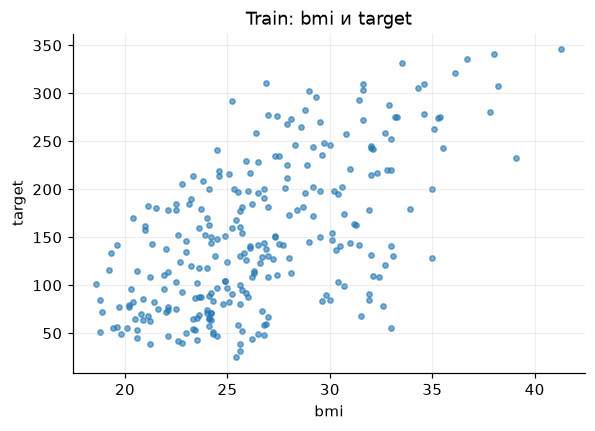

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
age,1.00,0.16,0.18,0.33,0.26,0.20,-0.02,0.17,0.28,0.29,0.19
sex,0.16,1.00,0.11,0.20,0.03,0.11,-0.33,0.33,0.15,0.17,0.04
bmi,0.18,0.11,1.00,0.36,0.25,0.28,-0.41,0.47,0.46,0.42,0.61
bp,0.33,0.20,0.36,1.00,0.26,0.18,-0.12,0.23,0.38,0.40,0.43
s1,0.26,0.03,0.25,0.26,1.00,0.89,0.07,0.54,0.52,0.33,0.18
s2,0.20,0.11,0.28,0.18,0.89,1.00,-0.17,0.65,0.30,0.29,0.15
s3,-0.02,-0.33,-0.41,-0.12,0.07,-0.17,1.00,-0.73,-0.38,-0.27,-0.40
s4,0.17,0.33,0.47,0.23,0.54,0.65,-0.73,1.00,0.63,0.40,0.42
s5,0.28,0.15,0.46,0.38,0.52,0.30,-0.38,0.63,1.00,0.47,0.52
s6,0.29,0.17,0.42,0.40,0.33,0.29,-0.27,0.40,0.47,1.00,0.38


Пары признаков с наибольшей |корреляцией|:
s1  s2    0.890
s3  s4   -0.726
s2  s4    0.646
s4  s5    0.627
dtype: float64


In [3]:
reg_train = reg_X_train.assign(target=reg_y_train)
print("Пропуски в train:", int(reg_train.isna().sum().sum()))
print("Повторяющиеся строки в train:", int(reg_train.duplicated().sum()))
display(reg_X_train.describe().T[["mean", "std", "min", "max"]])
print("Значения sex на train:", reg_X_train["sex"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(reg_X_train["bmi"], reg_y_train, s=12, alpha=0.6)
ax.set(xlabel="bmi", ylabel="target", title="Train: bmi и target")
plt.show()

reg_corr = reg_train.corr()
display(reg_corr.round(2))

reg_feat_corr = reg_corr.drop(index="target", columns="target")
reg_upper = reg_feat_corr.where(np.triu(np.ones(reg_feat_corr.shape, dtype=bool), k=1))
print("Пары признаков с наибольшей |корреляцией|:")
print(reg_upper.stack().sort_values(key=np.abs, ascending=False).head(4).round(3))


Пропусков и повторяющихся строк на train нет.

1. Масштабы сильно отличаются: `sex` принимает значения 1 и 2, у `s5` диапазон 3.5–6.1 (std ≈ 0.5), у `s4` — 2–9,
   а у `s1` 110–301 (std ≈ 35); `bp`, `s2`, `s6` — десятки–сотни. Коэффициенты при таких признаках нельзя сравнивать
   напрямую, а штраф Ridge/Lasso без стандартизации действовал бы на них по-разному (см. 1.3).
2. `sex` — категориальный признак, 1 и 2 — просто коды двух групп (143 и 122 человека на train). Их разность и порядок смысла не имеют.
   Для линейной модели со свободным членом одного столбца достаточно: $w\cdot\text{sex}+b$ даёт два уровня $b+w$ и $b+2w$,
   то же самое, что индикатор 0/1 со сдвинутым $b$. Два one-hot столбца в сумме дали бы столбец единиц, то есть были бы линейно зависимы со свободным членом.
3. Сильнее всего связаны `s1` и `s2` (корреляция 0.89), дальше `s3`–`s4` (−0.73). При такой связи почти одинаковый прогноз
   получается при разных сочетаниях коэффициентов, поэтому они неустойчивы и могут получаться большими и разного знака:
   в OLS (3.2) на стандартизованных признаках у `s1` −31.6, у `s2` +16.9, хотя с target оба коррелируют положительно (0.18 и 0.15).
   Трактовать коэффициент как «эффект `s1` при неизменном `s2`» нельзя — в данных `s1` почти не меняется отдельно от `s2`.
4. Нет. На диаграмме видна положительная связь (корреляция 0.61, разброс target растёт с `bmi`), но данные наблюдательные.
   `bmi` коррелирует с `bp`, `s3`–`s6` (|r| = 0.36–0.47), и общая связь может объясняться общими причинами (образ жизни и т.п.).
   Корреляция и коэффициент регрессии дают только ассоциацию; для причинного вывода нужен эксперимент или
   причинная модель с учётом конфаундеров.


### 3.2

Обучите на train `DummyRegressor(strategy="mean")` и `LinearRegression` (OLS).
Для OLS используйте `Pipeline` со `StandardScaler`.
Представьте RMSE обеих моделей на validation в таблице. Сохраните обученные модели.

$$\operatorname{RMSE}=\sqrt{\frac1m\sum_{i=1}^{m}(y_i-\hat y_i)^2}.$$

Интерпретируйте сравнение с Dummy. Объясните, почему среднее для Dummy
и параметры scaler должны вычисляться по train.

In [4]:
reg_dummy = reg_DummyRegressor(strategy="mean").fit(reg_X_train, reg_y_train)
reg_ols = reg_Pipeline([
    ("scaler", reg_StandardScaler()),
    ("model", reg_LinearRegression()),
]).fit(reg_X_train, reg_y_train)

reg_results_32 = pd.DataFrame({
    "train RMSE": [reg_rmse(reg_y_train, m.predict(reg_X_train)) for m in (reg_dummy, reg_ols)],
    "validation RMSE": [reg_rmse(reg_y_valid, m.predict(reg_X_valid)) for m in (reg_dummy, reg_ols)],
}, index=["Dummy (mean)", "OLS + StandardScaler"])
display(reg_results_32)
print("Среднее target: train =", round(reg_y_train.mean(), 2), "| validation =", round(reg_y_valid.mean(), 2))
print("Std target на validation:", round(reg_y_valid.std(ddof=0), 2))
display(pd.Series(reg_ols[-1].coef_, index=reg_X_train.columns)
        .to_frame("коэф. OLS (стандарт. признаки)").T.round(2))


,train RMSE,validation RMSE
Dummy (mean),77.3308,76.1614
OLS + StandardScaler,54.2849,49.1497


Среднее target: train = 151.03 | validation = 145.06
Std target на validation: 75.93


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
коэф. OLS (стандарт. признаки),0.85,-10.79,28.35,17.36,-31.57,16.92,0.7,6.82,28.36,1.49


| модель | validation RMSE |
|---|---|
| Dummy (mean) | 76.16 |
| OLS + StandardScaler | 49.15 |

OLS уменьшает ошибку на validation примерно на треть. RMSE Dummy почти равна стандартному отклонению target на validation (75.9) —
это уровень ошибки без использования признаков, так что признаки несут информацию. Но ошибка OLS всё ещё большая:
49 при значениях target на train от 25 до 346. То, что на train RMSE OLS (54.3) больше, чем на validation, — особенность этого
разбиения (в validation всего 88 объектов), а не признак переобучения или недообучения.

Среднее для Dummy и параметры scaler — это тоже обучение. Если считать их по validation или test, в модель попадает
информация из выборки, на которой её потом оценивают, и оценка качества получается слишком оптимистичной (утечка). На новых данных ответов
нет, а признаки нужно преобразовывать тем же самым преобразованием, что и при обучении, иначе коэффициенты будут
применяться к признакам в другой шкале.


### 3.3

Создайте копии train и validation, умножив только `bmi` на `1000`.
Сравните четыре варианта:

- OLS без стандартизации;
- OLS со `StandardScaler`;
- `Ridge(alpha=1000)` без стандартизации;
- `Ridge(alpha=1000)` со `StandardScaler`.

Для каждого варианта обучите отдельные модели на исходных и преобразованных
данных. Используйте validation в тех же единицах, что и соответствующий train.

Постройте четыре диаграммы: по горизонтали — прогноз на исходных данных,
по вертикали — прогноз после преобразования для того же объекта.
Добавьте диагональ $y=x$ и одинаковый масштаб осей внутри каждой панели.

1. В каких вариантах изменились прогнозы? Объясните результаты.
2. Как преобразование признака связано с коэффициентом при `bmi` и штрафом Ridge?
3. Какова роль стандартизации в этом эксперименте? Гарантирует ли она снижение ошибки при фиксированном `alpha`?

**Ожидание (3.3).** Прогнозы изменятся только у Ridge без стандартизации: OLS не зависит от масштаба признака, а StandardScaler убирает множитель 1000.

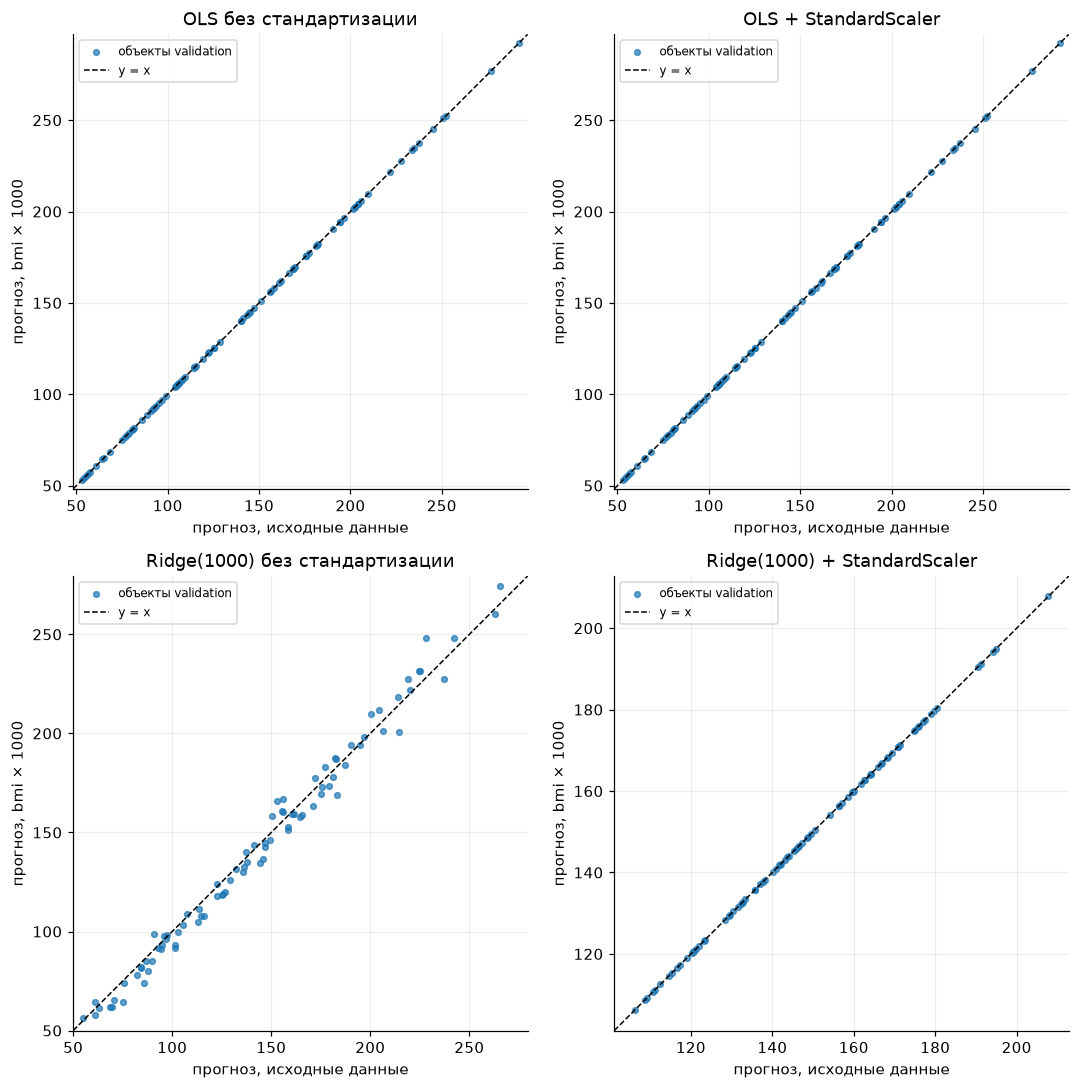

,max |Δ прогноза|,val RMSE исх.,val RMSE bmi×1000,coef bmi исх.,coef bmi ×1000
вариант,,,,,
OLS без стандартизации,6.48015e-12,49.1497,49.1497,6.38364,0.00638364
OLS + StandardScaler,1.84741e-13,49.1497,49.1497,28.3534,28.3534
Ridge(1000) без стандартизации,20.0203,52.2432,52.3256,5.63506,0.00725127
Ridge(1000) + StandardScaler,5.68434e-14,61.9594,61.9594,7.68209,7.68209


In [5]:
def reg_scale_bmi(X, factor=1000):
    X = X.copy()
    X["bmi"] = X["bmi"] * factor
    return X

reg_X_train_bmi = reg_scale_bmi(reg_X_train)
reg_X_valid_bmi = reg_scale_bmi(reg_X_valid)
reg_bmi_idx = list(reg_X_train.columns).index("bmi")

def reg_make_33(kind, scaled):
    model = reg_LinearRegression() if kind == "OLS" else reg_Ridge(alpha=1000)
    steps = [("scaler", reg_StandardScaler())] if scaled else []
    return reg_Pipeline(steps + [("model", model)])

reg_variants_33 = {
    "OLS без стандартизации": ("OLS", False),
    "OLS + StandardScaler": ("OLS", True),
    "Ridge(1000) без стандартизации": ("Ridge", False),
    "Ridge(1000) + StandardScaler": ("Ridge", True),
}

reg_rows_33 = []
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, (name, (kind, scaled)) in zip(axes.flat, reg_variants_33.items()):
    m_orig = reg_make_33(kind, scaled).fit(reg_X_train, reg_y_train)
    m_bmi = reg_make_33(kind, scaled).fit(reg_X_train_bmi, reg_y_train)
    p_orig = m_orig.predict(reg_X_valid)
    p_bmi = m_bmi.predict(reg_X_valid_bmi)
    reg_rows_33.append({
        "вариант": name,
        "max |Δ прогноза|": np.max(np.abs(p_orig - p_bmi)),
        "val RMSE исх.": reg_rmse(reg_y_valid, p_orig),
        "val RMSE bmi×1000": reg_rmse(reg_y_valid, p_bmi),
        "coef bmi исх.": m_orig[-1].coef_[reg_bmi_idx],
        "coef bmi ×1000": m_bmi[-1].coef_[reg_bmi_idx],
    })
    lims = [min(p_orig.min(), p_bmi.min()) - 5, max(p_orig.max(), p_bmi.max()) + 5]
    ax.scatter(p_orig, p_bmi, s=14, alpha=0.7, label="объекты validation")
    ax.plot(lims, lims, "k--", linewidth=1, label="y = x")
    ax.set(xlim=lims, ylim=lims, aspect="equal", title=name,
           xlabel="прогноз, исходные данные", ylabel="прогноз, bmi × 1000")
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

with pd.option_context("display.float_format", "{:.6g}".format):
    display(pd.DataFrame(reg_rows_33).set_index("вариант"))


1. Прогнозы изменились только у Ridge(1000) без стандартизации: точки заметно отходят от диагонали, максимальная разница ≈ 20.
   У трёх остальных вариантов разница порядка $10^{-12}$ — ошибки округления. Ожидание подтвердилось.
   - OLS без стандартизации: множество возможных прогнозов то же, коэффициент при `bmi` просто уменьшился в 1000 раз
     (6.38 → 0.00638), как в 1.3.
   - Со `StandardScaler` после стандартизации `bmi·1000` совпадает со стандартизованным `bmi`, модели получают одинаковые данные.
     Поэтому совпадают и коэффициенты (28.35 у OLS, 7.68 у Ridge).
2. Для того же прогноза коэффициент при `bmi·1000` должен быть в 1000 раз меньше, и его вклад в штраф $\alpha w^2$
   падает в $10^6$ раз — `bmi` фактически перестаёт штрафоваться. Ridge пользуется этим и даёт `bmi` больший эффект:
   в пересчёте на исходные единицы коэффициент вырос с 5.64 до 7.25 (0.00725·1000), остальные коэффициенты
   перераспределились. Из-за этого и изменились прогнозы.
3. Стандартизация делает результат независимым от единиц измерения и выравнивает шкалы, так что штраф одинаково
   действует на все признаки. Снижения ошибки при фиксированном `alpha` она не гарантирует: здесь Ridge(1000)
   со стандартизацией даёт validation RMSE 62.0, а без неё 52.2. Без стандартизации признаки с большим разбросом
   (`s1`, `s2`, `bp`, `s6`, их std 10–35) штрафуются слабо, и `alpha=1000` для них оказывается мягкой регуляризацией.
   После стандартизации тот же `alpha=1000` при 265 объектах уже сильно сжимает все коэффициенты (см. 3.4).
   После смены предобработки `alpha` надо подбирать заново.


### 3.4

На исходных признаках обучите модели в `Pipeline` со `StandardScaler`:

- Ridge: `alpha = [0.1, 1, 10, 100, 1000, 10000]`;
- Lasso: `alpha = [0.01, 0.1, 1, 3, 10, 30, 100]`, `max_iter=20000`.

Для каждого значения сохраните модель, коэффициенты, train RMSE и validation RMSE.
Постройте рисунок из четырёх панелей: в верхнем ряду — зависимости ошибок
от `alpha` для двух моделей, в нижнем — зависимости их коэффициентов от `alpha`.
Используйте логарифмическую ось `alpha` и линию нуля на графиках коэффициентов.

1. Как регуляризация влияет на train RMSE и validation RMSE? Объясните форму полученных кривых.
2. Проверьте по графикам утверждение: «При усилении Ridge-регуляризации каждый коэффициент не возрастает по модулю». Объясните результат и его связь с пунктом 1.2. Сравните поведение с Lasso: есть ли нулевые коэффициенты и что можно заключить о соответствующих признаках?
3. По документации [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) и [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) установите связь `alpha` с $\lambda$ из задачи 1. Можно ли сравнивать силу двух видов регуляризации по одинаковому числу `alpha`?
4. Интерпретируйте знак и величину коэффициента `bmi` у Lasso при `alpha=1`. Можно ли считать модуль коэффициента мерой важности признака? Обоснуйте ответ.

**Ожидание (3.4).** С ростом `alpha` train RMSE будет расти, validation RMSE сначала почти не изменится, а потом тоже вырастет; коэффициенты пойдут к нулю, у Lasso часть станет ровно нулевой.

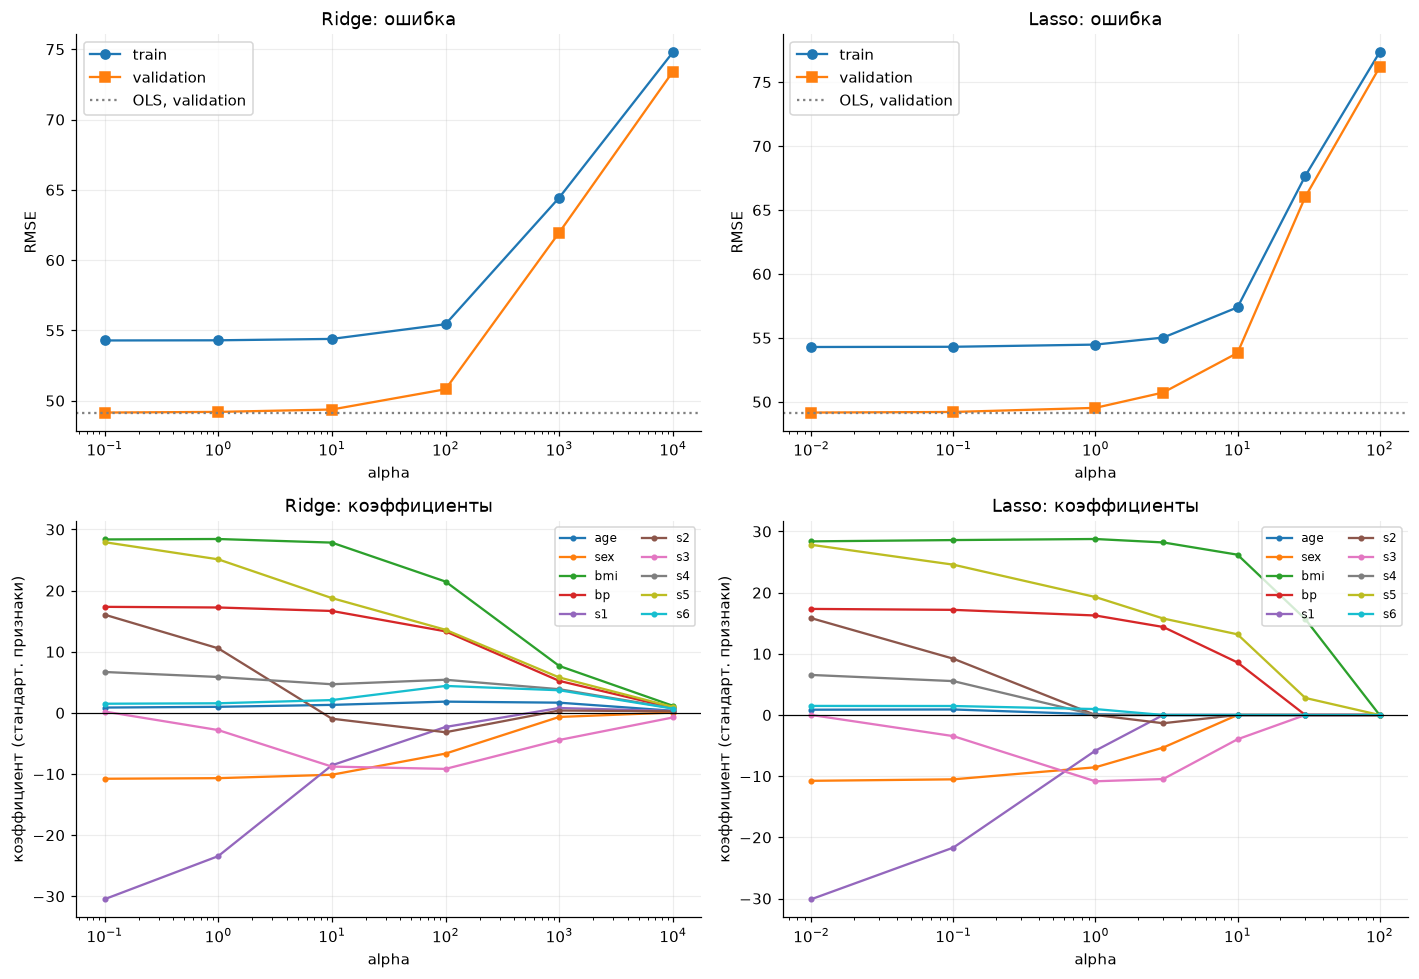

Ridge:


,train RMSE,validation RMSE
alpha,,
0.1,54.2851,49.1556
1.0,54.2966,49.2033
10.0,54.3951,49.3731
100.0,55.4401,50.8149
1000.0,64.4421,61.9594
10000.0,74.7826,73.4071


Lasso:


,train RMSE,validation RMSE,нулевых коэф.
alpha,,,
0.01,54.2853,49.1575,0
0.10,54.3023,49.2036,0
1.00,54.4733,49.5254,2
3.00,55.0220,50.7262,4
10.00,57.3864,53.8209,6
30.00,67.6650,66.0290,8
100.00,77.3308,76.1614,10


Ridge: признаки, у которых |coef| где-то растёт при увеличении alpha:
  age: рост при переходе к alpha = [1.0, 10.0, 100.0]
  bmi: рост при переходе к alpha = [1.0]
  s2: рост при переходе к alpha = [100.0]
  s3: рост при переходе к alpha = [1.0, 10.0, 100.0]
  s4: рост при переходе к alpha = [100.0]
  s6: рост при переходе к alpha = [1.0, 10.0, 100.0]
Ridge: ||w||_2 по alpha: [56.89 50.57 41.09 31.93 13.13  2.22]

Коэффициенты Ridge:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
alpha,,,,,,,,,,
0.1,0.87,-10.77,28.37,17.34,-30.48,16.07,0.22,6.69,27.93,1.50
1.0,0.99,-10.68,28.44,17.24,-23.44,10.56,-2.81,5.87,25.12,1.57
10.0,1.31,-10.12,27.85,16.67,-8.58,-0.95,-8.79,4.68,18.78,2.09
100.0,1.84,-6.66,21.48,13.34,-2.30,-3.17,-9.16,5.42,13.59,4.41
1000.0,1.67,-0.67,7.68,5.24,0.80,0.39,-4.43,3.87,5.80,3.70
10000.0,0.35,0.05,1.16,0.83,0.31,0.26,-0.75,0.77,0.97,0.70


Коэффициенты Lasso:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
alpha,,,,,,,,,,
0.01,0.86,-10.76,28.38,17.34,-30.11,15.83,0.00,6.55,27.82,1.48
0.10,0.90,-10.52,28.59,17.19,-21.67,9.20,-3.45,5.54,24.57,1.47
1.00,0.11,-8.55,28.76,16.26,-5.82,-0.00,-10.84,0.00,19.28,0.97
3.00,0.00,-5.32,28.20,14.38,-0.00,-1.35,-10.47,0.00,15.77,0.00
10.00,0.00,-0.00,26.20,8.59,-0.00,-0.00,-3.97,0.00,13.18,0.00
30.00,0.00,0.00,15.68,0.00,0.00,0.00,-0.00,0.00,2.79,0.00
100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Lasso, alpha=1: coef bmi = 28.764 | std bmi на train = 4.442


In [6]:
reg_features = list(reg_X_train.columns)
reg_ridge_alphas = [0.1, 1, 10, 100, 1000, 10000]
reg_lasso_alphas = [0.01, 0.1, 1, 3, 10, 30, 100]

def reg_fit_path(make_model, alphas):
    models, coefs, rows = {}, {}, []
    for alpha in alphas:
        model = reg_Pipeline([
            ("scaler", reg_StandardScaler()),
            ("model", make_model(alpha)),
        ]).fit(reg_X_train, reg_y_train)
        models[alpha] = model
        coefs[alpha] = model[-1].coef_
        rows.append({
            "alpha": alpha,
            "train RMSE": reg_rmse(reg_y_train, model.predict(reg_X_train)),
            "validation RMSE": reg_rmse(reg_y_valid, model.predict(reg_X_valid)),
        })
    coefs = pd.DataFrame(coefs, index=reg_features).T.rename_axis("alpha")
    return models, coefs, pd.DataFrame(rows).set_index("alpha")

reg_ridge_models, reg_ridge_coefs, reg_ridge_scores = reg_fit_path(
    lambda a: reg_Ridge(alpha=a), reg_ridge_alphas)
reg_lasso_models, reg_lasso_coefs, reg_lasso_scores = reg_fit_path(
    lambda a: reg_Lasso(alpha=a, max_iter=20000), reg_lasso_alphas)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, (name, scores, coefs) in enumerate([
    ("Ridge", reg_ridge_scores, reg_ridge_coefs),
    ("Lasso", reg_lasso_scores, reg_lasso_coefs),
]):
    ax = axes[0, col]
    ax.plot(scores.index, scores["train RMSE"], "o-", label="train")
    ax.plot(scores.index, scores["validation RMSE"], "s-", label="validation")
    ax.axhline(reg_results_32.loc["OLS + StandardScaler", "validation RMSE"],
               color="gray", linestyle=":", label="OLS, validation")
    ax.set(xscale="log", xlabel="alpha", ylabel="RMSE", title=f"{name}: ошибка")
    ax.legend()
    ax = axes[1, col]
    for feature in reg_features:
        ax.plot(coefs.index, coefs[feature], "o-", markersize=3, label=feature)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xscale="log", xlabel="alpha", ylabel="коэффициент (стандарт. признаки)",
           title=f"{name}: коэффициенты")
for ax in axes[1]:
    ax.legend(fontsize=8, ncol=2, loc="upper right")
fig.tight_layout()
plt.show()

print("Ridge:"); display(reg_ridge_scores)
print("Lasso:"); display(reg_lasso_scores.assign(
    **{"нулевых коэф.": (reg_lasso_coefs == 0).sum(axis=1)}))

reg_ridge_abs = reg_ridge_coefs.abs()
reg_ridge_growth = reg_ridge_abs.diff().gt(1e-12)
print("Ridge: признаки, у которых |coef| где-то растёт при увеличении alpha:")
for feature in reg_features:
    steps = reg_ridge_growth.index[reg_ridge_growth[feature]].tolist()
    if steps:
        print(f"  {feature}: рост при переходе к alpha = {steps}")
print("Ridge: ||w||_2 по alpha:", np.round(np.linalg.norm(reg_ridge_coefs, axis=1), 2))

print("\nКоэффициенты Ridge:"); display(reg_ridge_coefs.round(2))
print("Коэффициенты Lasso:"); display(reg_lasso_coefs.round(2))
print("Lasso, alpha=1: coef bmi =", round(reg_lasso_coefs.loc[1, "bmi"], 3),
      "| std bmi на train =", round(reg_lasso_models[1][0].scale_[reg_bmi_idx], 3))


1. Train RMSE растёт с `alpha` у обеих моделей: минимум ошибки на train даёт OLS, а штраф уводит от него (в 1.2 это доказано
   для Ridge). Validation RMSE при малых `alpha` почти равна OLS (49.16 у Ridge при 0.1 и у Lasso при 0.01) и дальше только растёт —
   ни одно значение `alpha` не улучшило validation по сравнению с OLS. При больших `alpha` обе ошибки подходят к уровню Dummy
   (≈ 77 на train, 76 на validation): коэффициенты почти нулевые, модель предсказывает среднее. Lasso при `alpha=100`
   обнуляет все коэффициенты и совпадает с Dummy. Такая форма кривых значит, что OLS здесь не переобучается
   (10 признаков на 265 объектов), и регуляризация добавляет только смещение.
2. Утверждение неверно. Норма вектора Ridge убывает (56.9 → 50.6 → 41.1 → 31.9 → 13.1 → 2.2), как и должно быть по 1.2,
   но отдельные коэффициенты могут расти по модулю: `s3` от 0.2 до −9.2 при `alpha` от 0.1 до 100, `s6` от 1.5 до 4.4,
   `age` от 0.9 до 1.8; `s2` меняет знак (16.1 → −1.0 → −3.2). Причина — корреляция признаков. Штраф сильнее всего сжимает
   большие коэффициенты (пару `s1`/`s2`, затем `s5`, `bmi`), и их вклад частично перекладывается на коррелированные с ними признаки
   с малыми коэффициентами. `s6` и `age` положительно связаны с `bmi`, `bp`, `s5` (r = 0.18–0.47), поэтому их коэффициенты растут.
   Комбинация $-30\,s_1+16\,s_2$, которую использует почти не регуляризованная модель, коррелирует с `s3` (r ≈ −0.28), и когда она
   сжимается, коэффициент `s3` уходит в минус.
   В 1.1 признаки ортонормированы, и там $\hat w=c/(1+\lambda)$ сжимает каждую координату отдельно; в общем случае
   монотонность есть только у нормы.

   У Lasso появляются точные нули: при `alpha=1` — 2 (`s2`, `s4`), при 3 — 4, при 10 — 6, при 30 остаются только `bmi` и `s5`.
   Это не значит, что обнулённые признаки не связаны с target: у `s4` корреляция с target 0.42, но его информация уже есть
   в `s3`, `s5`, `bmi`. Можно сказать только, что при данном `alpha` признак мало что добавляет к остальным, причём при
   коррелированных признаках выбор, какой из них оставить, неустойчив.
3. По документации `Ridge` минимизирует $\|y-Xw\|_2^2+\alpha\|w\|_2^2$; это $2n\cdot L_{\mathrm{Ridge}}$ при $\alpha=n\lambda$.
   `Lasso` минимизирует $\frac1{2n}\|y-Xw\|_2^2+\alpha\|w\|_1$, то есть ровно $L_{\mathrm{Lasso}}$, $\alpha=\lambda$.
   При $n=265$ `alpha=1` для Ridge соответствует $\lambda\approx0.004$, а для Lasso $\lambda=1$. К тому же штрафы разной формы
   (квадрат и модуль), поэтому одинаковые `alpha` не означают одинаковую силу регуляризации. На графиках это видно:
   Ridge заметно портится с `alpha` ≈ 100, Lasso — уже с 3–10.
4. У Lasso при `alpha=1` коэффициент `bmi` ≈ 28.8 при стандартизованном признаке. Плюс означает, что при фиксированных
   остальных признаках больший `bmi` связан с большим прогнозом. Рост `bmi` на одно стандартное отклонение (4.44 на train)
   увеличивает прогноз примерно на 28.8, то есть ≈ 6.5 на единицу `bmi`. Это связь внутри модели, а не причинный эффект (3.1.4).

   Модуль коэффициента — мера важности только с оговорками. Сравнивать модули можно лишь при стандартизованных признаках
   (иначе модуль зависит от единиц, 1.3). И даже тогда он зависит от коррелированных соседей и от `alpha`: у `s1` в OLS
   модуль 31.6 (больше, чем у `bmi`), а у Lasso при `alpha=1` уже 5.8; у `s2` — от 16.9 до 0. Для `bmi` вывод устойчивый:
   коэффициент ≈ 28 при всех `alpha` до 3, а при `alpha=30` он остаётся самым большим (15.7, кроме него ненулевой только `s5` = 2.8). Но в общем случае важность лучше проверять
   по росту ошибки на validation при удалении или перемешивании признака.


### 3.5

По результатам 3.2 и 3.4 выберите OLS или одну из моделей Ridge/Lasso
со `StandardScaler`. Зафиксируйте и обоснуйте выбор до обращения к test.

Вычислите test RMSE выбранной обученной модели. Постройте график фактических
значений против прогнозов с диагональю либо остатков против прогнозов с линией нуля.

Интерпретируйте график и укажите ограничение модели или проведённого эксперимента.

In [7]:
reg_candidates = pd.concat([
    pd.DataFrame({"модель": ["OLS"], "alpha": [np.nan],
                  "validation RMSE": [reg_results_32.loc["OLS + StandardScaler", "validation RMSE"]]}),
    reg_ridge_scores.reset_index().assign(модель="Ridge")[["модель", "alpha", "validation RMSE"]],
    reg_lasso_scores.reset_index().assign(модель="Lasso")[["модель", "alpha", "validation RMSE"]],
], ignore_index=True)
display(reg_candidates.sort_values("validation RMSE").head(6))


,модель,alpha,validation RMSE
0,OLS,NaN,49.1497
1,Ridge,0.10,49.1556
7,Lasso,0.01,49.1575
2,Ridge,1.00,49.2033
8,Lasso,0.10,49.2036
3,Ridge,10.00,49.3731


**Выбор (до обращения к test).** Беру OLS со `StandardScaler` из 3.2 (`reg_ols`). У неё наименьшая validation RMSE — 49.15.
Ridge при `alpha=0.1` и Lasso при `alpha=0.01` дают 49.16: разница в сотых — это шум, а лишний гиперпараметр ничего не даёт.
Более сильная регуляризация на validation только хуже.

Test RMSE выбранной модели: 56.97
Test RMSE Dummy (для масштаба): 76.91


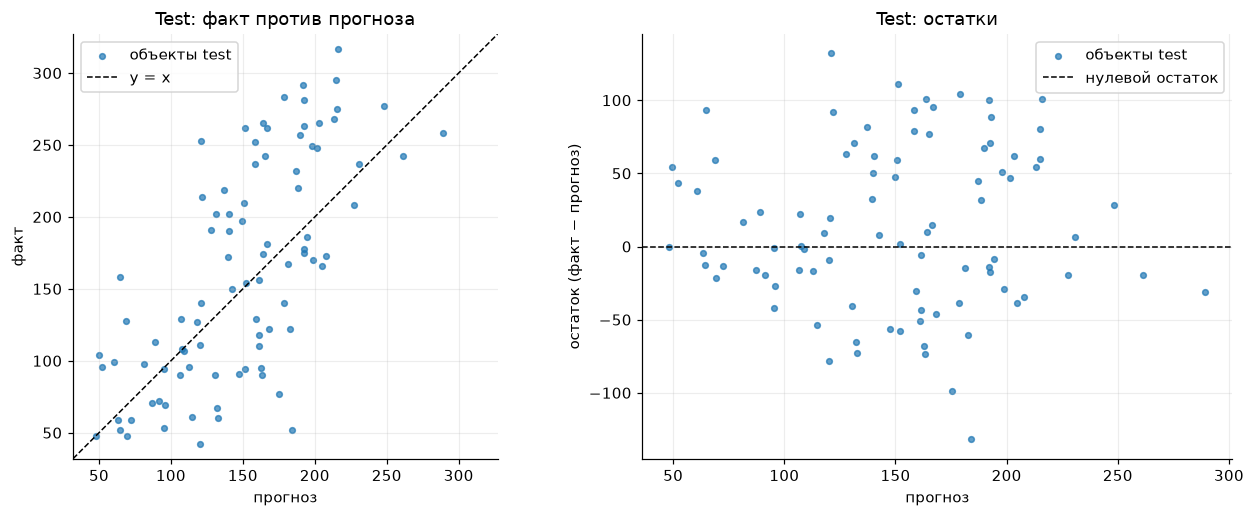

In [8]:
reg_final_model = reg_ols
reg_test_pred = reg_final_model.predict(reg_X_test)
reg_test_rmse = reg_rmse(reg_y_test, reg_test_pred)
print(f"Test RMSE выбранной модели: {reg_test_rmse:.2f}")
print(f"Test RMSE Dummy (для масштаба): {reg_rmse(reg_y_test, reg_dummy.predict(reg_X_test)):.2f}")

reg_resid = reg_y_test - reg_test_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
lims = [min(reg_y_test.min(), reg_test_pred.min()) - 10, max(reg_y_test.max(), reg_test_pred.max()) + 10]
axes[0].scatter(reg_test_pred, reg_y_test, s=14, alpha=0.7, label="объекты test")
axes[0].plot(lims, lims, "k--", linewidth=1, label="y = x")
axes[0].set(xlim=lims, ylim=lims, aspect="equal", xlabel="прогноз", ylabel="факт",
            title="Test: факт против прогноза")
axes[0].legend()
axes[1].scatter(reg_test_pred, reg_resid, s=14, alpha=0.7, label="объекты test")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1, label="нулевой остаток")
axes[1].set(xlabel="прогноз", ylabel="остаток (факт − прогноз)", title="Test: остатки")
axes[1].legend()
fig.tight_layout()
plt.show()


Test RMSE OLS — 56.97 (Dummy на test — 76.91). Это больше, чем на validation (49.15), и чуть больше, чем на train (54.28).
Модель одна и та же, гиперпараметров у OLS нет, а RMSE на validation и test (по 88–89 объектов) отличается на 8 единиц.
Это не подгонка под validation, а разброс оценки: на таких маленьких выборках RMSE сильно зависит от того, какие объекты
в них попали, и 49 на validation оказалось оптимистичной оценкой.

На графиках: точки широко разбросаны вокруг диагонали, остатки до ±130. Прогнозы сжаты к среднему: у 15 из 17 пациентов
с фактическим target ≥ 250 прогноз 120–216, а у пациентов с target < 100 прогноз завышен в 23 случаях из 26. Разброс остатков
при прогнозах до 100 меньше (std ≈ 36), чем при прогнозах 100–230 (std ≈ 57–63), то есть дисперсия ошибки неоднородна.

Ограничения: линейная модель по 10 признакам объясняет только часть разброса и систематически недооценивает тяжёлые
случаи; нелинейности и взаимодействия признаков не учитываются. Кроме того, все выводы получены на одном разбиении
с маленькими validation и test, поэтому разница в несколько единиц RMSE между моделями ничего не доказывает — надёжнее
было бы использовать кросс-валидацию.

## Задача 4. Классификация

Используйте набор Wisconsin Diagnostic Breast Cancer. Он содержит 30 числовых
характеристик клеточных ядер. Во всех пунктах используйте только `mean radius`
и `mean texture`. Целевая переменная перекодирована:
`1 = malignant` (злокачественная опухоль), `0 = benign` (доброкачественная опухоль).

Рассматриваются четыре метода:

- логистическая регрессия — модель вероятности класса с сигмоидой от линейной комбинации признаков;
- kNN — классификация по меткам ближайших соседей;
- SVM с RBF-ядром — метод опорных векторов с гауссовым ядром;
- дерево решений — последовательность разбиений по значениям признаков.

Стратифицированное разбиение train / validation / test — 60 / 20 / 20%.
Финальная оценка на test выполняется в пункте 4.5.

[Описание данных](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).

In [9]:
from IPython.display import Markdown as cls_Markdown
from sklearn.datasets import load_breast_cancer as cls_load_data
from sklearn.dummy import DummyClassifier as cls_DummyClassifier
from sklearn.linear_model import LogisticRegression as cls_LogisticRegression
from sklearn.neighbors import KNeighborsClassifier as cls_KNeighborsClassifier
from sklearn.svm import SVC as cls_SVC
from sklearn.tree import DecisionTreeClassifier as cls_DecisionTreeClassifier
from sklearn.pipeline import Pipeline as cls_Pipeline
from sklearn.preprocessing import StandardScaler as cls_StandardScaler
from sklearn.model_selection import train_test_split as cls_train_test_split
from sklearn.metrics import (
    balanced_accuracy_score as cls_balanced_accuracy_score,
    precision_score as cls_precision_score,
    recall_score as cls_recall_score,
    confusion_matrix as cls_confusion_matrix,
    ConfusionMatrixDisplay as cls_ConfusionMatrixDisplay,
)

cls_data = cls_load_data(as_frame=True)
cls_features = ["mean radius", "mean texture"]
cls_X = cls_data.data[cls_features].copy()
cls_y = (cls_data.target == 0).astype(int).rename("malignant")
cls_X_dev, cls_X_test, cls_y_dev, cls_y_test = cls_train_test_split(
    cls_X, cls_y, test_size=0.20, stratify=cls_y, random_state=SEED
)
cls_X_train, cls_X_val, cls_y_train, cls_y_val = cls_train_test_split(
    cls_X_dev, cls_y_dev, test_size=0.25, stratify=cls_y_dev, random_state=SEED
)
assert set(cls_X_train.index).isdisjoint(cls_X_val.index)
assert set(cls_X_train.index).isdisjoint(cls_X_test.index)
assert set(cls_X_val.index).isdisjoint(cls_X_test.index)
print("Число объектов train / validation / test:",
      len(cls_X_train), len(cls_X_val), len(cls_X_test))

Число объектов train / validation / test: 341 114 114


Функция `cls_plot_boundaries(models, titles=None, radius_multipliers=None, mark_errors=True)`
принимает словарь «название → обученная модель» и строит области предсказанных классов.
На графике отображаются train-объекты и, при `mark_errors=True`, ошибки validation.
`titles` задаёт подписи, `radius_multipliers` — множители радиуса на входе каждой модели.
Координаты графика соответствуют исходным единицам признаков.

In [10]:
cls_colors = {0: "#2a788e", 1: "#c95a47"}
cls_names = {0: "benign (0)", 1: "malignant (1)"}
cls_low = cls_X_train.min() - 0.06 * (cls_X_train.max() - cls_X_train.min())
cls_high = cls_X_train.max() + 0.06 * (cls_X_train.max() - cls_X_train.min())
cls_xx, cls_yy = np.meshgrid(
    np.linspace(cls_low.iloc[0], cls_high.iloc[0], 180),
    np.linspace(cls_low.iloc[1], cls_high.iloc[1], 180),
)
cls_grid = pd.DataFrame({cls_features[0]: cls_xx.ravel(), cls_features[1]: cls_yy.ravel()})

def cls_draw_boundary(model, ax, title, radius_multiplier=1, mark_errors=True):
    grid = cls_grid.copy()
    grid[cls_features[0]] *= radius_multiplier
    pred = model.predict(grid).reshape(cls_xx.shape)
    ax.contourf(cls_xx, cls_yy, pred, levels=[-0.5, 0.5, 1.5],
                colors=[cls_colors[0], cls_colors[1]], alpha=0.19)
    if hasattr(model, "decision_function"):
        score = model.decision_function(grid).reshape(cls_xx.shape)
        ax.contour(cls_xx, cls_yy, score, levels=[0], colors="#333333", linewidths=1)
    else:
        ax.contour(cls_xx, cls_yy, pred, levels=[0.5], colors="#333333", linewidths=1)
    for label in [0, 1]:
        mask = cls_y_train == label
        ax.scatter(cls_X_train.loc[mask, cls_features[0]],
                   cls_X_train.loc[mask, cls_features[1]],
                   color=cls_colors[label], s=15, alpha=0.65, label=cls_names[label])
    if mark_errors:
        val = cls_X_val.copy()
        val[cls_features[0]] *= radius_multiplier
        wrong = model.predict(val) != cls_y_val
        ax.scatter(cls_X_val.loc[wrong, cls_features[0]], cls_X_val.loc[wrong, cls_features[1]],
                   color="black", marker="x", s=30, linewidths=1, label="ошибка validation")
    ax.set(xlabel=cls_features[0], ylabel=cls_features[1], title=title,
           xlim=(cls_low.iloc[0], cls_high.iloc[0]),
           ylim=(cls_low.iloc[1], cls_high.iloc[1]))


def cls_plot_boundaries(models, titles=None, radius_multipliers=None, mark_errors=True):
    # models: словарь «название → обученная модель»; функция ничего не обучает.
    if not 1 <= len(models) <= 4:
        raise ValueError("Передайте от одной до четырёх обученных моделей")
    titles = {} if titles is None else titles
    radius_multipliers = {} if radius_multipliers is None else radius_multipliers
    columns = min(2, len(models))
    rows = (len(models) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5.5 * columns, 4 * rows),
                             sharex=True, sharey=True, squeeze=False)
    for ax, (name, model) in zip(axes.flat, models.items()):
        cls_draw_boundary(model, ax, titles.get(name, name),
                          radius_multiplier=radius_multipliers.get(name, 1),
                          mark_errors=mark_errors)
    for ax in list(axes.flat)[len(models):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle("Точки — train" + ("; крестики — ошибки validation" if mark_errors else ""))
    fig.tight_layout()
    plt.show()

### 4.1

На train определите диапазоны двух признаков и доли классов.
Постройте диаграмму `mean radius` × `mean texture` с цветом по классу.

1. В каких областях ожидаете ошибки классификатора по этим двум признакам? Обоснуйте ответ.
2. Вычислите accuracy, recall класса 1 и balanced accuracy для правила «всегда класс большинства». Сравните информативность этих метрик.

В пунктах 4.2 и 4.5 основная метрика — balanced accuracy:
$\mathrm{BA}=(\mathrm{recall}_0+\mathrm{recall}_1)/2$.

,mean radius,mean texture
min,6.9810,9.7100
max,27.4200,39.2800
mean,14.1634,19.4288
std,3.5993,4.3612


Доли классов на train: {0: 0.628, 1: 0.372}
Доли классов на validation: {0: 0.623, 1: 0.377}


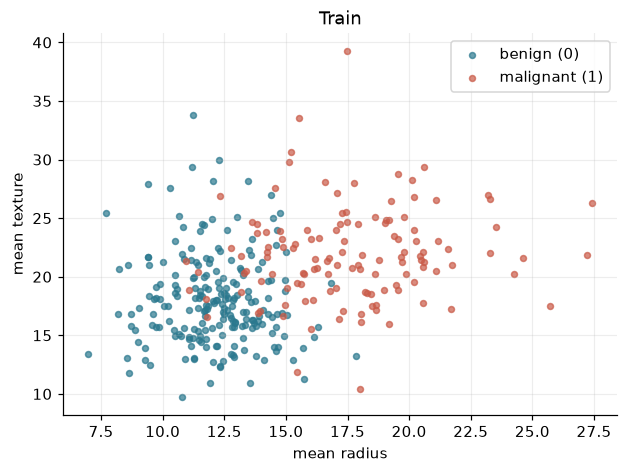

Класс большинства: 0


,accuracy,recall класса 1,balanced accuracy
выборка,,,
train,0.6276,0.0,0.5
validation,0.6228,0.0,0.5


In [11]:
display(cls_X_train.agg(["min", "max", "mean", "std"]))
print("Доли классов на train:", cls_y_train.value_counts(normalize=True).round(3).to_dict())
print("Доли классов на validation:", cls_y_val.value_counts(normalize=True).round(3).to_dict())

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for label in [0, 1]:
    mask = cls_y_train == label
    ax.scatter(cls_X_train.loc[mask, "mean radius"], cls_X_train.loc[mask, "mean texture"],
               color=cls_colors[label], s=15, alpha=0.7, label=cls_names[label])
ax.set(xlabel="mean radius", ylabel="mean texture", title="Train")
ax.legend()
plt.show()

cls_majority = int(cls_y_train.mode()[0])
cls_rows_41 = []
for split, y in [("train", cls_y_train), ("validation", cls_y_val)]:
    pred = np.full(len(y), cls_majority)
    cls_rows_41.append({
        "выборка": split,
        "accuracy": float((pred == y).mean()),
        "recall класса 1": cls_recall_score(y, pred, zero_division=0),
        "balanced accuracy": cls_balanced_accuracy_score(y, pred),
    })
print("Класс большинства:", cls_majority)
display(pd.DataFrame(cls_rows_41).set_index("выборка"))


На train `mean radius` от 6.98 до 27.42, `mean texture` от 9.71 до 39.28. Доли классов: 62.8% benign, 37.2% malignant
(на validation почти так же — разбиение стратифицированное).

1. Злокачественные опухоли в основном крупнее: при radius > 17 почти все объекты класса 1, при radius < 11 — почти все класса 0.
   Текстура немного помогает — при одинаковом радиусе у класса 1 она в среднем выше, поэтому граница должна идти наклонно.
   Ошибки ожидаю в полосе radius ≈ 12–15.5 при texture ≈ 15–25: там классы сильно перемешаны, и по двум признакам их не разделить
   никакой моделью. Кроме того, будут ошибки на отдельных нетипичных точках (benign с radius ≈ 17–18, malignant с radius ≈ 11–12).
2. Правило «всегда 0»: accuracy 0.628 на train и 0.623 на validation, recall класса 1 = 0, balanced accuracy = 0.5.
   Accuracy выглядит неплохо, хотя не найдено ни одной злокачественной опухоли, — она просто равна доле большинства.
   Recall класса 1 сразу показывает, что правило бесполезно, но сам по себе он тоже неполон (правило «всегда 1» дало бы recall 1).
   BA учитывает оба класса и для любого константного правила равна 0.5 при любом балансе, поэтому 0.5 — удобная точка отсчёта.


### 4.2

Сравните логистическую регрессию, kNN, SVM с RBF-ядром и дерево решений.
Самостоятельно выберите гиперпараметры для исследования и подберите их значения
по validation balanced accuracy. Для каждого метода исследуйте не менее трёх
значений хотя бы одного гиперпараметра, определяющего сложность или структуру
модели. Сохраните выбранную модель и представьте результаты сравнения.

Постройте границы выбранных моделей. Можно использовать функцию
`cls_plot_boundaries(models)`, передав словарь обученных моделей.

Отдельно исследуйте влияние глубины дерева на train и validation balanced accuracy.
Диапазон глубин выберите самостоятельно и представьте результаты на графике.

1. Обоснуйте выбор настроек и объясните различия форм границ четырёх моделей.
2. Выберите одну область ошибок validation и объясните её через форму границы.
3. Интерпретируйте зависимости метрик от глубины дерева.

LogReg


,0,1,2,3,4,5
C,0.001,0.010,0.100,1.000,10.000,100.000
train BA,0.500,0.805,0.869,0.881,0.885,0.885
val BA,0.500,0.760,0.844,0.860,0.860,0.853


kNN


,0,1,2,3,4,5,6,7
n_neighbors,75.000,45.000,25.000,15.000,9.000,5.000,3.000,1.000
train BA,0.869,0.877,0.891,0.892,0.876,0.894,0.910,1.000
val BA,0.858,0.886,0.872,0.872,0.879,0.832,0.849,0.804


SVM RBF


C,0.1,1.0,10.0,100.0
gamma,,,,
0.1,0.823,0.874,0.872,0.886
0.5,0.874,0.879,0.867,0.874
2.0,0.893,0.879,0.832,0.790
10.0,0.663,0.846,0.821,0.785


Tree


min_samples_leaf,1,5,20
max_depth,,,
1,0.865,0.865,0.865
2,0.842,0.842,0.865
3,0.853,0.842,0.890
4,0.821,0.821,0.890
5,0.807,0.814,0.890
6,0.839,0.841,0.890
8,0.820,0.841,0.890


Выбранные настройки:


,параметры,train BA,val BA
метод,,,
LogReg,C=1,0.8814,0.8601
kNN,n_neighbors=45,0.8766,0.8858
SVM RBF,"gamma=2, C=0.1",0.8931,0.8929
Tree,"max_depth=3, min_samples_leaf=20",0.8957,0.8904


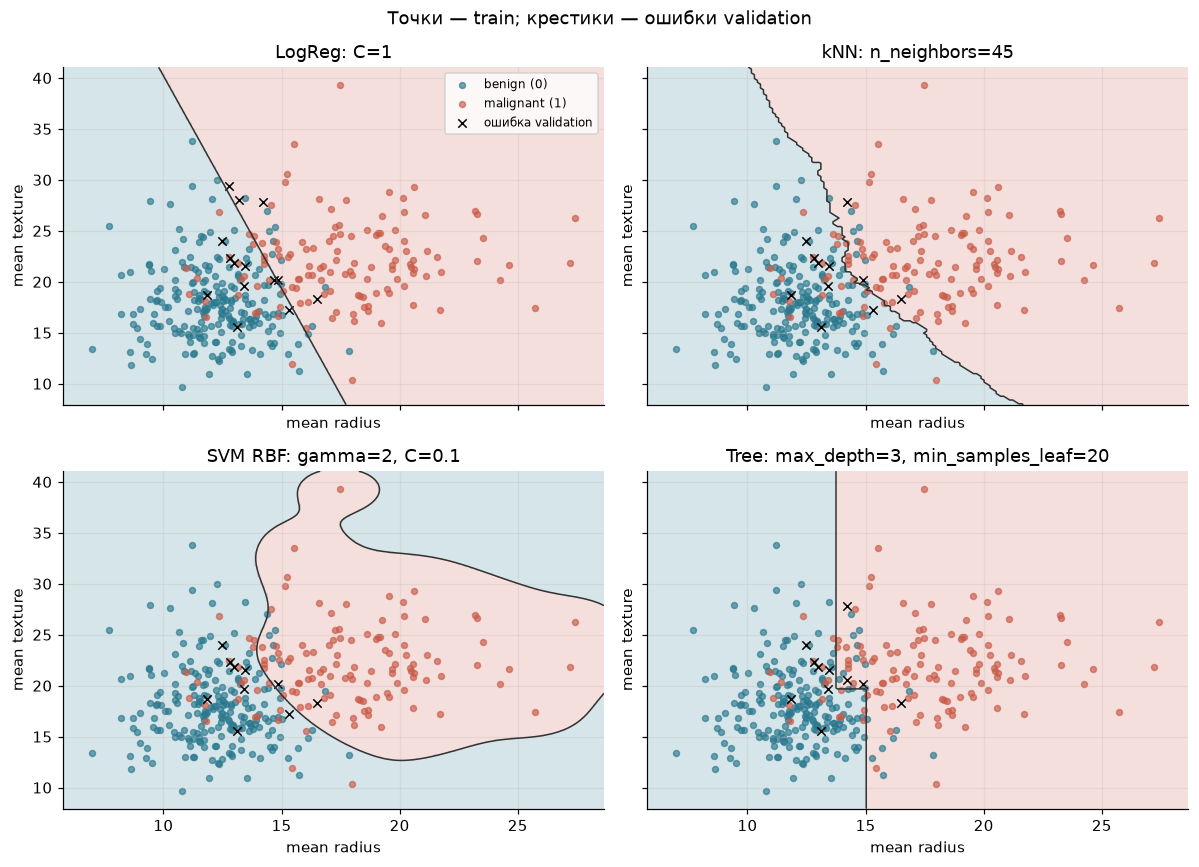

In [12]:
def cls_scaled(model):
    return cls_Pipeline([("scaler", cls_StandardScaler()), ("model", model)])

# Сетки упорядочены от более простых моделей к более сложным:
# при равной validation BA берётся первая, то есть более простая модель.
cls_grids = {
    "LogReg": [({"C": C}, lambda C=C: cls_scaled(cls_LogisticRegression(C=C)))
               for C in [0.001, 0.01, 0.1, 1, 10, 100]],
    "kNN": [({"n_neighbors": k}, lambda k=k: cls_scaled(cls_KNeighborsClassifier(n_neighbors=k)))
            for k in [75, 45, 25, 15, 9, 5, 3, 1]],
    "SVM RBF": [({"gamma": g, "C": C}, lambda g=g, C=C: cls_scaled(cls_SVC(kernel="rbf", gamma=g, C=C)))
                for g in [0.1, 0.5, 2, 10] for C in [0.1, 1, 10, 100]],
    "Tree": [({"max_depth": d, "min_samples_leaf": leaf},
              lambda d=d, leaf=leaf: cls_DecisionTreeClassifier(
                  max_depth=d, min_samples_leaf=leaf, random_state=SEED))
             for d in [1, 2, 3, 4, 5, 6, 8] for leaf in [20, 5, 1]],
}

cls_search = {}
cls_best_models, cls_best_rows = {}, []
for method, grid in cls_grids.items():
    rows, models = [], []
    for params, make in grid:
        model = make().fit(cls_X_train, cls_y_train)
        models.append(model)
        rows.append({**params,
                     "train BA": cls_balanced_accuracy_score(cls_y_train, model.predict(cls_X_train)),
                     "val BA": cls_balanced_accuracy_score(cls_y_val, model.predict(cls_X_val))})
    table = pd.DataFrame(rows)
    cls_search[method] = table
    best = int(table["val BA"].idxmax())
    cls_best_models[method] = models[best]
    cls_best_rows.append({"метод": method,
                          "параметры": ", ".join(f"{k}={v}" for k, v in grid[best][0].items()),
                          "train BA": table.loc[best, "train BA"],
                          "val BA": table.loc[best, "val BA"]})

for method, table in cls_search.items():
    print(method)
    if method == "SVM RBF":
        display(table.pivot(index="gamma", columns="C", values="val BA").round(3))
    elif method == "Tree":
        display(table.pivot(index="max_depth", columns="min_samples_leaf", values="val BA").round(3))
    else:
        display(table.round(3).T)

cls_summary_42 = pd.DataFrame(cls_best_rows).set_index("метод")
print("Выбранные настройки:")
display(cls_summary_42)

cls_plot_boundaries(cls_best_models,
                    titles={m: f"{m}: {cls_summary_42.loc[m, 'параметры']}" for m in cls_best_models})


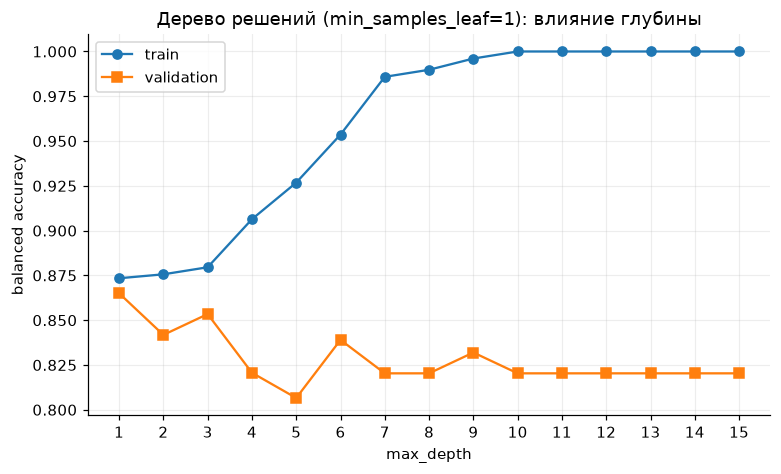

,реальная глубина,листьев,train BA,val BA
max_depth,,,,
1,1,2,0.873,0.865
2,2,4,0.876,0.842
3,3,8,0.880,0.853
4,4,14,0.906,0.821
5,5,21,0.927,0.807
6,6,30,0.954,0.839
7,7,40,0.986,0.820
8,8,43,0.990,0.820
9,9,47,0.996,0.832


In [13]:
cls_depths = list(range(1, 16))
cls_depth_rows = []
for depth in cls_depths:
    tree = cls_DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(cls_X_train, cls_y_train)
    cls_depth_rows.append({
        "max_depth": depth,
        "реальная глубина": tree.get_depth(),
        "листьев": tree.get_n_leaves(),
        "train BA": cls_balanced_accuracy_score(cls_y_train, tree.predict(cls_X_train)),
        "val BA": cls_balanced_accuracy_score(cls_y_val, tree.predict(cls_X_val)),
    })
cls_depth_table = pd.DataFrame(cls_depth_rows).set_index("max_depth")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cls_depth_table.index, cls_depth_table["train BA"], "o-", label="train")
ax.plot(cls_depth_table.index, cls_depth_table["val BA"], "s-", label="validation")
ax.set(xlabel="max_depth", ylabel="balanced accuracy",
       title="Дерево решений (min_samples_leaf=1): влияние глубины")
ax.set_xticks(cls_depths)
ax.legend()
plt.show()
display(cls_depth_table.round(3))


**Выбор настроек.** kNN, SVM и логистическая регрессия — в `Pipeline` со `StandardScaler`: kNN и RBF-ядро зависят от расстояний,
а у логистической регрессии от масштаба зависит действие L2-штрафа. Дереву масштаб не нужен (см. 4.3).
Сетки упорядочены от простых моделей к сложным, при одинаковой validation BA берётся более простая.

- LogReg: `C` от 0.001 до 100. Лучшие `C=1` и `C=10` (0.860), взял `C=1`. При `C=0.001` штраф сжимает веса почти в ноль,
  модель предсказывает один класс (BA 0.5).
- kNN: `n_neighbors` от 75 до 1. Лучшее `k=45` (0.886). При `k=1` train BA = 1, а validation 0.80 — переобучение.
- SVM RBF: сетка `gamma` × `C`. Лучшее `gamma=2, C=0.1` (0.893). При больших `gamma` и `C` (граница подстраивается под точки)
  validation падает до 0.79.
- Дерево: `max_depth` 1–8 × `min_samples_leaf` {20, 5, 1}. С `min_samples_leaf=20` validation BA 0.890 при любой глубине от 3,
  взял глубину 3. С `min_samples_leaf` 1 и 5 при глубине от 2 качество хуже (0.81–0.85).

В validation 114 объектов, из них 43 класса 1; одна ошибка на классе 1 меняет BA примерно на 0.012. Число ошибок на validation:
SVM — 10 (8 FN, 2 FP), kNN — 11 (8 FN, 3 FP), дерево — 11 (7 FN, 4 FP), логистическая регрессия — 14 (9 FN, 5 FP).
То есть kNN, SVM и дерево отличаются на одну ошибку.

1. Формы границ:
   - LogReg — прямая $w^\top x+b=0$ (стандартизация линейна и это не меняет). Идёт наклонно: больше радиус или текстура —
     ближе к классу 1, но вес радиуса намного больше.
   - kNN(45) — ломаная неровная линия, повторяющая локальное соотношение классов среди соседей. В центре она близка к прямой
     LogReg, но загибается в зоне перекрытия и на краях, где данных мало.
   - SVM RBF — гладкая кривая. Класс 1 — замкнутая область вокруг облака malignant. Вдали от данных (очень большой радиус
     при texture < 13 или > 30) модель предсказывает класс 0: решающая функция там стремится к свободному члену (≈ −0.06 < 0).
     Это артефакт экстраполяции — таких объектов в train нет, а по смыслу они скорее злокачественные.
   - Дерево — ступенчатая граница из отрезков, параллельных осям: radius > 15.05 → класс 1, radius < 13.8 → класс 0,
     между ними решает texture > 19.74.
2. Возьму область radius ≈ 11.8–13.4, texture ≈ 15–24. Там лежат 7 злокачественных опухолей из validation, и их ошибочно
   относят к benign все четыре модели. У дерева это видно напрямую: всё с radius < 13.8 — класс 0, какая бы ни была текстура.
   У логистической регрессии при texture 15–24 прямая проходит на radius ≈ 14–16, и эти точки оказываются левее неё. Сдвинуть границу влево
   нельзя без потерь: в этом прямоугольнике на train 53 доброкачественные опухоли и только 6 злокачественных, и модели с
   ограниченной сложностью правильно ставят туда класс 0. Это ошибки из-за перекрытия классов в двух выбранных признаках,
   а не из-за неудачной формы границы.
3. (Дерево с `min_samples_leaf=1`.) Train BA растёт с глубиной и с глубины 10 равна 1 — дерево с 48 листьями запоминает
   train, дальше расти ему некуда. Validation BA лучшая уже при глубине 1 (0.865, одно разбиение по радиусу) и дальше
   колеблется в диапазоне 0.81–0.85 без роста. Разрыв между train и validation растёт: новые разбиения подстраиваются под
   отдельные точки в зоне перекрытия, и это переобучение. Колебания validation (провал при 5, подъём при 6) — шум маленькой выборки.
   Поэтому в сетке лучше всего сработало ограничение `min_samples_leaf=20`, а не глубина.


### 4.3

Создайте копии train и validation, умножив только `mean radius` на `100`.
На исходных и преобразованных данных обучите по одной версии:

- kNN с `n_neighbors=9` без стандартизации;
- kNN с `n_neighbors=9` и `StandardScaler`;
- дерева с `max_depth=3`, `random_state=SEED`.

Для каждого метода вычислите долю validation-объектов, у которых изменилась
предсказанная метка. Изобразите две границы kNN без стандартизации
в исходных координатах. При использовании `cls_plot_boundaries` передайте
`radius_multipliers={название_преобразованной_модели: 100}` и `mark_errors=False`.

Объясните результаты для каждого метода и роль масштаба признаков.

**Ожидание (4.3).** kNN без стандартизации изменит часть меток, потому что расстояние будет определяться почти только радиусом; у kNN со StandardScaler и у дерева метки не изменятся.

,доля изменённых меток,val BA исх.,val BA radius×100
метод,,,
kNN(9) без стандартизации,0.061,0.886,0.851
kNN(9) + StandardScaler,0.000,0.879,0.879
Tree(max_depth=3),0.000,0.853,0.853


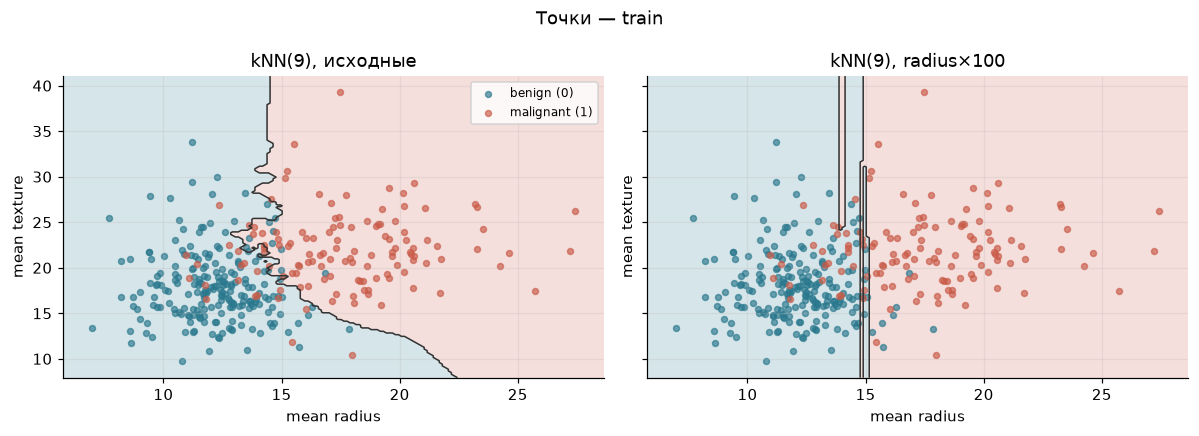

In [14]:
def cls_scale_radius(X, factor=100):
    X = X.copy()
    X["mean radius"] = X["mean radius"] * factor
    return X

cls_X_train_r = cls_scale_radius(cls_X_train)
cls_X_val_r = cls_scale_radius(cls_X_val)

cls_makers_43 = {
    "kNN(9) без стандартизации": lambda: cls_KNeighborsClassifier(n_neighbors=9),
    "kNN(9) + StandardScaler": lambda: cls_scaled(cls_KNeighborsClassifier(n_neighbors=9)),
    "Tree(max_depth=3)": lambda: cls_DecisionTreeClassifier(max_depth=3, random_state=SEED),
}
cls_models_43, cls_rows_43 = {}, []
for name, make in cls_makers_43.items():
    m_orig = make().fit(cls_X_train, cls_y_train)
    m_r = make().fit(cls_X_train_r, cls_y_train)
    cls_models_43[name] = (m_orig, m_r)
    p_orig, p_r = m_orig.predict(cls_X_val), m_r.predict(cls_X_val_r)
    cls_rows_43.append({"метод": name,
                        "доля изменённых меток": float((p_orig != p_r).mean()),
                        "val BA исх.": cls_balanced_accuracy_score(cls_y_val, p_orig),
                        "val BA radius×100": cls_balanced_accuracy_score(cls_y_val, p_r)})
display(pd.DataFrame(cls_rows_43).set_index("метод").round(3))

cls_knn_orig, cls_knn_r = cls_models_43["kNN(9) без стандартизации"]
cls_plot_boundaries(
    {"kNN(9), исходные": cls_knn_orig, "kNN(9), radius×100": cls_knn_r},
    radius_multipliers={"kNN(9), radius×100": 100},
    mark_errors=False,
)


Доля validation-объектов с изменившейся меткой: kNN без стандартизации — 6.1% (7 из 114), kNN со `StandardScaler` — 0, дерево — 0.
Ожидание подтвердилось.

- kNN без стандартизации считает евклидово расстояние. После умножения на 100 std радиуса стала ≈ 360, а у текстуры ≈ 4.4,
  так что соседи выбираются практически только по радиусу. На графике граница превратилась в вертикальные полосы — текстура
  почти перестала влиять. Validation BA упала с 0.886 до 0.851.
- kNN со `StandardScaler`: scaler делит радиус на его std, множитель 100 сокращается, модель видит те же данные.
- Дерево: каждое разбиение — это сравнение одного признака с порогом, $x_j\le\theta\iff100x_j\le100\theta$.
  Порядок объектов по признаку не меняется, поэтому дерево строит те же разбиения, только пороги по радиусу умножаются на 100.

Масштаб признаков важен для методов на расстояниях (kNN, SVM RBF) и для моделей со штрафом на веса, и не важен для деревьев.
В исходных данных std радиуса и текстуры близки (3.6 и 4.4), поэтому kNN(9) без стандартизации работал нормально;
после умножения на 100 это уже не так.


### 4.4

Для обученной логистической регрессии из 4.2 получите оценки вероятности
класса 1 на validation. Для порога $t$ используйте правило $\hat y=1$ при $p(x)\ge t$.
Постройте зависимости precision и recall от порога на отрезке $[0,1]$.

Для порогов `0.2, 0.5, 0.8` составьте таблицу: precision, recall, FP, FN.
При отсутствии положительных предсказаний используйте `zero_division=0`.

1. Как зависят FP и FN от порога? Исследуйте монотонность precision и recall. Объясните смысл `zero_division=0`.
2. Какой из трёх порогов вы выберете, если пропуск класса 1 значительно дороже ложного срабатывания? Какие данные нужны для численного обоснования выбора?
3. Как изменение порога влияет на вероятностные оценки, ранжирование объектов и границу классификации?

**Ожидание (4.4).** С ростом порога FP и recall уменьшаются, FN растёт, precision в основном растёт, но не обязательно монотонно.

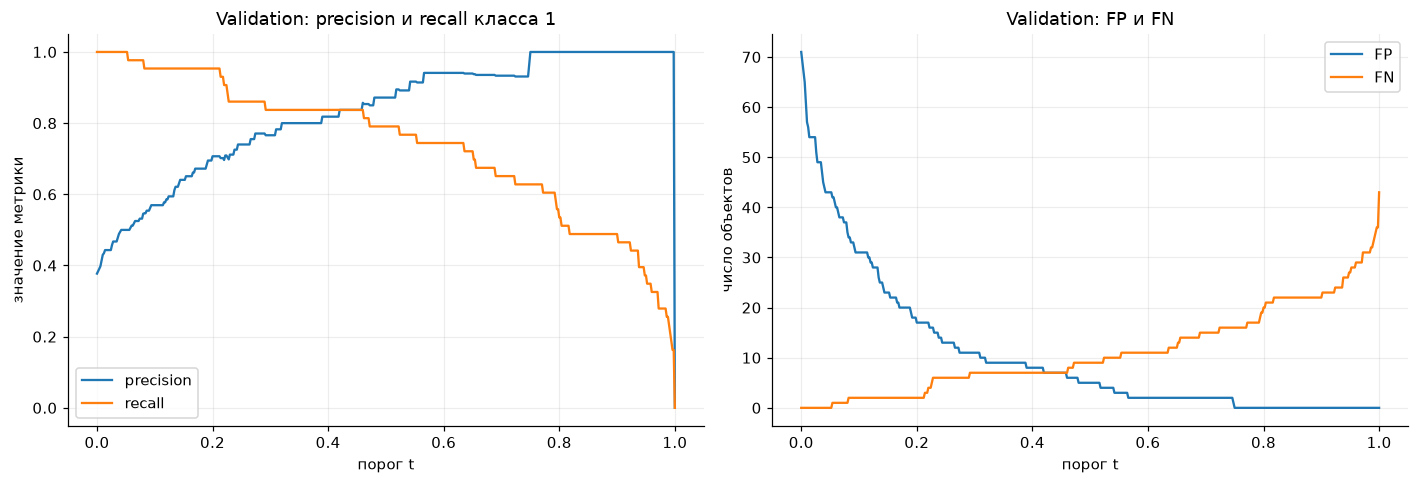

,precision,recall,TP,FP,FN,TN
порог,,,,,,
0.2,0.707,0.953,41,17,2,54
0.5,0.872,0.791,34,5,9,66
0.8,1.000,0.535,23,0,20,71


Число участков, где precision падает при росте t: 15
Recall не возрастает по t: True
Максимальная вероятность на validation: 1.0


In [15]:
cls_logreg = cls_best_models["LogReg"]
cls_proba_val = cls_logreg.predict_proba(cls_X_val)[:, 1]

def cls_threshold_metrics(t):
    pred = (cls_proba_val >= t).astype(int)
    tn, fp, fn, tp = cls_confusion_matrix(cls_y_val, pred, labels=[0, 1]).ravel()
    return {"порог": t,
            "precision": cls_precision_score(cls_y_val, pred, zero_division=0),
            "recall": cls_recall_score(cls_y_val, pred, zero_division=0),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

cls_thresholds = np.linspace(0, 1, 501)
cls_curve = pd.DataFrame([cls_threshold_metrics(t) for t in cls_thresholds]).set_index("порог")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(cls_curve.index, cls_curve["precision"], label="precision")
axes[0].plot(cls_curve.index, cls_curve["recall"], label="recall")
axes[0].set(xlabel="порог t", ylabel="значение метрики", title="Validation: precision и recall класса 1")
axes[0].legend()
axes[1].plot(cls_curve.index, cls_curve["FP"], label="FP")
axes[1].plot(cls_curve.index, cls_curve["FN"], label="FN")
axes[1].set(xlabel="порог t", ylabel="число объектов", title="Validation: FP и FN")
axes[1].legend()
fig.tight_layout()
plt.show()

display(pd.DataFrame([cls_threshold_metrics(t) for t in [0.2, 0.5, 0.8]]).set_index("порог").round(3))

cls_prec = cls_curve["precision"].to_numpy()
print("Число участков, где precision падает при росте t:", int((np.diff(cls_prec) < -1e-12).sum()))
print("Recall не возрастает по t:", bool((np.diff(cls_curve["recall"].to_numpy()) <= 1e-12).all()))
print("Максимальная вероятность на validation:", round(cls_proba_val.max(), 3))


| порог | precision | recall | FP | FN |
|---|---|---|---|---|
| 0.2 | 0.707 | 0.953 | 17 | 2 |
| 0.5 | 0.872 | 0.791 | 5 | 9 |
| 0.8 | 1.000 | 0.535 | 0 | 20 |

1. С ростом порога класс 1 предсказывается реже: FP не возрастает (71 при $t=0$, то есть все benign, и 0 начиная с $t\approx0.75$),
   FN не убывает (от 0 до 43 при $t=1$). Recall монотонно не возрастает, это проверено по сетке порогов. Precision в целом растёт,
   но не монотонно: на сетке 15 мест, где она падает. 14 из них — настоящие падения (например, около 0.21–0.23, 0.46–0.47, 0.64–0.72):
   порог проходит через объект класса 1, TP уменьшается, а FP остаётся прежним, как в контрпримере 2.1. Пятнадцатое — при $t=1$.
   Там положительных предсказаний нет (максимальная вероятность 0.99999 < 1) и precision $=0/0$ не определена; `zero_division=0` подставляет вместо неё 0. Это соглашение, а не
   реальная точность, поэтому последняя точка графика падает в 0.
2. Если пропустить злокачественную опухоль намного хуже, чем отправить здорового человека на дообследование, выбираю $t=0.2$:
   FN = 2 вместо 9 и 20, ценой 17 ложных срабатываний. Для численного обоснования нужны стоимости $c_{FN}$ и $c_{FP}$ (хотя бы их
   отношение) — тогда порог $t^*=c_{FP}/(c_{FP}+c_{FN})$ из 2.2, если вероятности модели откалиброваны. Ещё нужна доля
   злокачественных опухолей там, где модель будут применять, и больше размеченных данных: на 43 положительных объектах
   разница между близкими порогами — это одна-две ошибки.
3. Порог не меняет саму модель: вероятности $p(x)$ те же, ранжирование объектов то же. Меняется только правило решения, а с ним
   граница классификации: для логистической регрессии это та же прямая $w^\top x+b=\ln\frac{t}{1-t}$, сдвинутая параллельно.
   При $t=0.2$ она смещается в сторону класса 0, и область класса 1 расширяется.


### 4.5

По validation balanced accuracy выберите одну из четырёх моделей с подобранными
в пункте 4.2 гиперпараметрами. Зафиксируйте и обоснуйте выбор до обращения к test. Используйте обычный `predict`.

Оцените на test выбранную модель и `DummyClassifier(strategy="most_frequent")`,
обученный на train. Представьте balanced accuracy, precision и recall класса 1
в таблице и постройте матрицу ошибок выбранной модели.
Для precision используйте `zero_division=0`.

1. Какие ошибки преобладают? Как соотносятся матрица ошибок и рассчитанные метрики?
2. Сравните test и validation balanced accuracy. Интерпретируйте различие.

In [16]:
display(cls_summary_42.sort_values("val BA", ascending=False))


,параметры,train BA,val BA
метод,,,
SVM RBF,"gamma=2, C=0.1",0.8931,0.8929
Tree,"max_depth=3, min_samples_leaf=20",0.8957,0.8904
kNN,n_neighbors=45,0.8766,0.8858
LogReg,C=1,0.8814,0.8601


**Выбор (до обращения к test).** По validation BA лучшая — SVM RBF (`gamma=2, C=0.1`), 0.893. Дерево (0.890) и kNN (0.886)
отстают меньше чем на одну ошибку класса 1, но правило выбора — максимальная validation BA, так что беру SVM. Недостаток SVM
учитываю: странная граница вдали от данных (см. 4.2), в test таких объектов, скорее всего, нет, поэтому на метриках он может не сказаться.

,test BA,precision (1),recall (1)
модель,,,
SVM RBF,0.869,1.0,0.738
Dummy (most_frequent),0.500,0.0,0.000


Validation BA выбранной модели: 0.893


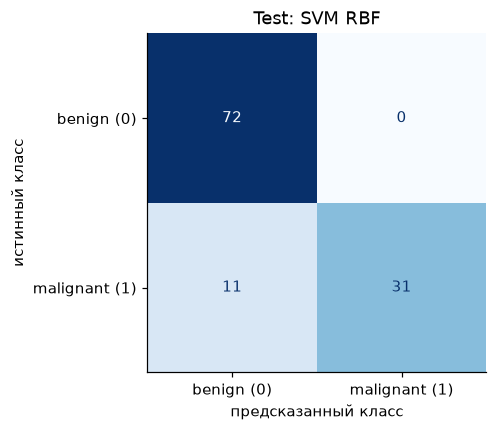

In [17]:
cls_final_name = "SVM RBF"
cls_final_model = cls_best_models[cls_final_name]
cls_dummy = cls_DummyClassifier(strategy="most_frequent").fit(cls_X_train, cls_y_train)

cls_rows_45 = []
for name, model in [(cls_final_name, cls_final_model), ("Dummy (most_frequent)", cls_dummy)]:
    pred = model.predict(cls_X_test)
    cls_rows_45.append({"модель": name,
                        "test BA": cls_balanced_accuracy_score(cls_y_test, pred),
                        "precision (1)": cls_precision_score(cls_y_test, pred, zero_division=0),
                        "recall (1)": cls_recall_score(cls_y_test, pred, zero_division=0)})
display(pd.DataFrame(cls_rows_45).set_index("модель").round(3))
print(f"Validation BA выбранной модели: {cls_summary_42.loc[cls_final_name, 'val BA']:.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4))
cls_ConfusionMatrixDisplay.from_predictions(
    cls_y_test, cls_final_model.predict(cls_X_test),
    display_labels=["benign (0)", "malignant (1)"], cmap="Blues", ax=ax, colorbar=False)
ax.set(title=f"Test: {cls_final_name}", xlabel="предсказанный класс", ylabel="истинный класс")
ax.grid(False)
plt.show()


| модель | test BA | precision (1) | recall (1) |
|---|---|---|---|
| SVM RBF | 0.869 | 1.000 | 0.738 |
| Dummy (most_frequent) | 0.500 | 0.000 | 0.000 |

1. Все ошибки — ложноотрицательные: 11 злокачественных опухолей из 42 предсказаны как доброкачественные, ложных тревог нет
   (TN = 72, FP = 0, TP = 31). Отсюда precision = 31/31 = 1, recall = 31/42 = 0.738, recall класса 0 = 72/72 = 1,
   BA = (1 + 0.738)/2 = 0.869. Для медицинской задачи это худший тип ошибок; при применении стоило бы сдвинуть порог решающей
   функции в сторону класса 1, как в 4.4. Dummy никогда не предсказывает класс 1: recall 0, precision 0 по `zero_division=0`, BA 0.5.
2. Test BA 0.869, validation BA 0.893 — на test хуже на 0.024. На validation у SVM было 8 FN и 2 FP, на test 11 FN и 0 FP:
   recall класса 1 упал с 0.81 до 0.74, а recall класса 0 вырос с 0.97 до 1.
   Модель выбиралась по максимуму validation BA среди многих вариантов, поэтому эта оценка немного завышена: выигрывает
   та настройка, которой повезло на данном validation. Кроме того, на выборке из 114 объектов такие колебания — в пределах
   случайности. Test — честная оценка, но тоже шумная.

## Выводы

Сформулируйте выводы по работе, укажите ограничения экспериментов
и предложите дальнейшее исследование.

- В регрессии на Diabetes линейная модель заметно лучше константы (RMSE 49 против 76 на validation, 57 против 77 на test),
  но ошибка остаётся большой. Регуляризация Ridge/Lasso на этом разбиении не улучшила validation: признаков мало, OLS не переобучается.
- Масштаб признаков важен для Ridge/Lasso и kNN: без стандартизации штраф и расстояние зависят от единиц измерения (3.3, 4.3).
  OLS и деревьям масштаб не важен. Стандартизация сама по себе ошибку не уменьшает, после неё нужно заново подбирать `alpha`.
- При усилении Ridge убывает норма вектора коэффициентов, но не каждый коэффициент; Lasso даёт точные нули. Коэффициенты
  коррелированных признаков (`s1`, `s2`) неустойчивы, их нельзя читать как важность или причинный эффект.
- В классификации по двум признакам kNN, SVM и дерево дают на validation BA ≈ 0.89, логистическая регрессия 0.86. Основные ошибки —
  злокачественные опухоли среднего размера, которые по радиусу и текстуре неотличимы от доброкачественных. Выбранная SVM
  на test ошибается только пропусками класса 1. Порог решения определяет баланс FP/FN, и выбирать его нужно по стоимостям ошибок.

Ограничения: одно фиксированное разбиение и маленькие validation/test (88–89 объектов в регрессии, 114 в классификации) — разница между моделями
на уровне одной-двух ошибок не значима; в классификации использованы только 2 из 30 признаков; стоимости ошибок неизвестны,
а калибровка вероятностей не проверялась.

Дальше можно: заменить одно разбиение на кросс-валидацию и оценить разброс метрик; в регрессии попробовать нелинейные
признаки/модели и преобразование target (дисперсия ошибок неоднородна); в классификации добавить остальные признаки
(например, `mean concave points`, `worst radius`), подобрать порог по стоимостям и проверить калибровку вероятностей.

## Документация

- [Линейные модели](https://scikit-learn.org/stable/modules/linear_model.html).
- [Pipeline](https://scikit-learn.org/stable/modules/compose.html#pipeline).
- [Метод ближайших соседей](https://scikit-learn.org/stable/modules/neighbors.html).
- [Деревья решений](https://scikit-learn.org/stable/modules/tree.html).
- [Метрики](https://scikit-learn.org/stable/modules/model_evaluation.html).